# Trabalho Prático de Mineração de Dados — Fase 2
## Utilização de LLMs e Análise Comparativa com Diretrizes de IA Responsável

**Disciplina:** Mineração de Dados  
**Grupo:** Grupo 13 - Arthur Faria (2024013915), Felipe Pereira (2024080051), Giordano Liporati (2023027963), João Vaz (2023099166)  
**Dataset:** Spotify Tracks Dataset - https://www.kaggle.com/datasets/yashdev01/spotify-tracks-dataset

**Tarefa de mineração:** Agrupamento  
**Data da entrega:** 24/05/2026


# 0. Controle da entrega e rastreabilidade

Esta seção registra informações mínimas para tornar o trabalho rastreável e auditável.

| Item | Valor |
|---|---|
| Nome do dataset | Spotify Tracks Dataset |
| Link público do dataset | https://www.kaggle.com/datasets/yashdev01/spotify-tracks-dataset |
| Número de linhas | 114.000 |
| Número de colunas | 21 |
| Tarefa de mineração | Agrupamento |
| LLM usada na Trilha A | ChatGPT |
| LLM usada na Trilha B | ChatGPT |
| Link da conversa — Trilha A | Ver lista detalhada abaixo |
| Link da conversa — Trilha B | Ver lista detalhada abaixo |

**Links das interações (Trilha A - Baseline):**
* **Business Understanding:** https://chatgpt.com/share/6a0a6dc1-e85c-83e9-bca0-77e1a174583e
* **Data Preparation:** https://chatgpt.com/share/6a0daf90-a374-83e9-8491-33d7158ec569
* **Modeling:** [COMPLETAR]

**Links das interações (Trilha B - Guiada):**
* **Business Understanding:** https://chatgpt.com/share/6a0a6da3-c68c-83e9-b691-c4c6ac2269e2
* **Data Preparation:** https://chatgpt.com/share/6a0db005-57d8-83e9-88e0-5bc7332732f9
* **Modeling:** [COMPLETAR]

## Diretrizes de IA responsável escolhidas

| Diretriz | Justificativa da escolha | Como será explicitada na Trilha B |
|---|---|---|
| **Eficiência e escalabilidade** | O dataset possui um volume considerável (> 114 mil linhas e 21 colunas). Algoritmos de agrupamento baseados em distância (como Hierárquico ou K-Means padrão sem otimização) podem causar estouro de memória (RAM) e gargalos de processamento. | Exigiremos no prompt que a LLM sugira abordagens focadas em otimização de memória, como o uso de redução de dimensionalidade (PCA). |
| **Usabilidade e acessibilidade** | Algoritmos de clustering geram rótulos puramente matemáticos (ex: "Cluster 0", "Cluster 1"). Para agregar valor de negócio (ex: criação de playlists no Spotify), os resultados devem ser intuitivos e fáceis de interpretar para perfis não técnicos. | Solicitaremos no prompt que a LLM estruture formas visuais e didáticas de perfilar os clusters (ex: propondo gráficos de radar/teia para as médias das *features*) e que traduza os resultados numéricos . |




In [1]:
# Configurações iniciais do notebook
# Esta célula centraliza imports e parâmetros gerais.
# O grupo deve adaptar os caminhos, nomes de colunas e tipo de tarefa.

import os
import time
import json
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

# Caminho para o dataset.
# Exemplos:
# DATA_PATH = "dados/dataset.csv"
# DATA_PATH = "/content/dataset.csv"
DATA_PATH = "spotify-tracks-dataset.csv"

# Tipo de tarefa do TP.
# Opções sugeridas:
# - "padroes_frequentes"
# - "agrupamento"
# - "classificacao"
TASK_TYPE = "agrupamento"

# Coluna-alvo, se aplicável.
# Para padrões frequentes ou agrupamento, normalmente pode ser None.
TARGET_COLUMN = None  # Exemplo: "classe"

# Coluna ou conjunto de colunas usadas para gerar transações, se o TP for de padrões frequentes.
TRANSACTION_COLUMN = None

print("Configuração carregada.")
print(f"Tarefa definida: {TASK_TYPE}")


Configuração carregada.
Tarefa definida: agrupamento


# 1. Business Understanding




## 1.1 Descrição do problema de negócio

- **Contexto:** Na indústria de *streaming* de áudio, plataformas como o Spotify lidam com catálogos na casa dos milhões de faixas. A categorização tradicional baseada apenas em "gêneros" (Rock, Pop, Jazz) é frequentemente subjetiva, engessada e não captura a verdadeiro perfil acústico das músicas.
- **Problema:** Como segmentar de forma objetiva um catálogo musical massivo agrupando faixas que possuem características sonoras semelhantes (como energia, dançabilidade e acústica), independentemente do seu gênero oficial ou popularidade do artista?
- **Possíveis interessados:** Curadores de *playlists*, times de engenharia de recomendação, departamento de marketing e os próprios usuários da plataforma.
- **Decisões apoiadas pela análise:** A segmentação permitirá automatizar a criação de *playlists* contextuais , aprimorar sistemas de recomendação e auxiliar artistas/gravadoras a entenderem em qual nicho acústico seus lançamentos se encaixam.
- **Limitações iniciais conhecidas:** O dataset possui cerca de 114 mil registros. Algoritmos de agrupamento baseados em distância possuem complexidade computacional alta, o que pode gerar estouro de memória (RAM) caso métodos ingênuos sejam aplicados. Além disso, as variáveis de áudio possuem escalas diferentes (ex: *tempo* varia de 0 a 200+, enquanto *danceability* varia de 0 a 1), exigindo padronização prévia rigorosa.

## 1.2 Objetivo do dataset, origem e características gerais

### Objetivo do dataset

O dataset captura as métricas e *features* de áudio de milhares de músicas, calculadas pelos algoritmos de extração de características da própria API do Spotify. O propósito é permitir a análise quantitativa da estrutura musical (acústica, instrumentalidade, positividade, andamento) para modelagem de padrões.

### Origem dos dados

Os dados foram extraídos da API oficial do Spotify pelo usuário Yash Dev e disponibilizados publicamente na plataforma Kaggle.

Link público: https://www.kaggle.com/datasets/yashdev01/spotify-tracks-dataset

### Características do dataset

| Coluna | Tipo esperado | Descrição | Relevância para a tarefa |
|---|---|---|---|
| **track_id / track_name** | Texto | Identificador e nome da música. | **Baixa** para a clusterização em si, mas **Alta** para a usabilidade (identificar o que caiu no cluster). |
| **danceability** | Numérico contínuo | O quão adequada a faixa é para dançar (0.0 a 1.0). | **Alta.** Define o ritmo e a estabilidade da batida. |
| **energy** | Numérico contínuo | Medida de intensidade e atividade da faixa (0.0 a 1.0). | **Alta.** Separa músicas calmas de músicas agitadas/barulhentas. |
| **acousticness** | Numérico contínuo | Probabilidade de a música ser acústica (sem instrumentos eletrônicos). | **Alta.**  |
| **instrumentalness** | Numérico contínuo | Previsão de ausência de vocais na música. | **Alta.**  |
| **valence** | Numérico contínuo | A "positividade" musical transmitida (0.0=triste/tensa, 1.0=feliz/eufórica). | **Alta.**  |
| **tempo** | Numérico contínuo | O andamento estimado da faixa em batidas por minuto (BPM). | **Alta.** Determina a velocidade percebida da música. |

### Relação com o problema de negócio

Este dataset é ideal para a tarefa de Agrupamento porque traduz conceitos musicais abstratos em vetores numéricos contínuos. Isso permite que algoritmos geométricos meçam distâncias e encontrem os nichos acústicos com precisão matemática, gerando valor direto para a inteligência de recomendação.


## 1.3 Diretrizes selecionadas e hipótese experimental

### Diretrizes selecionadas

| Diretriz | Por que é pertinente ao problema? | Possível efeito esperado na solução da LLM |
|---|---|---|
| **Eficiência e escalabilidade** | O agrupamento de 114.000 instâncias em um espaço multidimensional exige o cálculo pesado de distâncias inter-pontos. Algoritmos clássicos não-otimizados fatalmente esgotarão a memória ou o tempo hábil. | Espera-se que a LLM recomende pré-processamentos para redução de dimensionalidade (ex: PCA) e sugira algoritmos operáveis em lote (como o `MiniBatchKMeans`) em vez do K-Means padrão. |
| **Usabilidade e acessibilidade** | O algoritmo retornará rótulos matemáticos vazios de significado ("Cluster 0", "Cluster 1"). O time de negócios precisa de perfis claros para montar *playlists*. | Espera-se que a LLM proponha visualizações interpretáveis (ex: gráficos de radar ou de teia para mostrar a média das *features*) e deduza nomes comerciais/personas para os clusters (ex: "Cluster Relax e Foco"). |

### Hipótese experimental

Esperamos que, ao explicitar as diretrizes de **Eficiência/Escalabilidade** e **Usabilidade/Acessibilidade**, a LLM proponha uma solução com **menor custo computacional** e **maior interpretabilidade de negócio**, em comparação com a solução baseline. Na trilha sem diretrizes, hipotetizamos que a IA sugerirá uma modelagem padrão (K-means com hiperparâmetros fixos e gráficos de dispersão genéricos 2D). Na trilha guiada, acreditamos que a IA recomendará ativamente o uso de processamento em lotes (`MiniBatchKMeans`) e a criação de perfis visuais acompanhados de uma tradução descritiva para que o time de marketing possa facilmente acionar os resultados.


## 1.4 Interações com LLM — Business Understanding

### Trilha A — baseline

**Modelo utilizado:** ChatGPT-5.3  
**Data de acesso:** 17/05/2026

**Link da conversa:** https://chatgpt.com/share/6a0a6dc1-e85c-83e9-bca0-77e1a174583e

**Subtarefa:** obter apoio para formular o Business Understanding.

#### Prompt principal — baseline

```text
Eu estou fazendo um trabalho de Mineração de Dados com o dataset "Spotify Tracks Dataset"(https://www.kaggle.com/datasets/yashdev01/spotify-tracks-dataset).
A tarefa é Agrupamento (Clustering) com o objetivo de segmentar as músicas por similaridade de áudio (danceability, energy, valence, etc).

Ajude-me a formular o Business Understanding, incluindo objetivo do dataset,
origem dos dados, características gerais e relação com o problema.
```

#### Síntese da resposta da LLM

A resposta ofereceu uma visão correta, porém teórica e genérica, sobre o uso do dataset do Spotify para segmentação baseada em *audio features* (características sonoras como *danceability* e *energy*). Destacou o valor de negócio para criação de *playlists* baseadas em *mood* (humor) e sistemas de recomendação não dependentes do gênero musical. Contudo, a LLM não recomendou algoritmos específicos de agrupamento, ignorou o risco computacional de calcular distâncias geométricas para mais de 100 mil registros e não forneceu táticas claras de como apresentar os clusters formados para a equipe de negócios.

---

### Trilha B — guiada por diretrizes

**Modelo utilizado:** ChatGPT-5.3

**Data de acesso:** 17/05/2026   

**Link da conversa:** https://chatgpt.com/share/6a0a6da3-c68c-83e9-b691-c4c6ac2269e2

**Subtarefa:** obter apoio para formular o Business Understanding considerando as diretrizes escolhidas.

#### Prompt principal — guiado

```text
Eu estou fazendo um trabalho de Mineração de Dados com o dataset "Spotify Tracks Dataset"(https://www.kaggle.com/datasets/yashdev01/spotify-tracks-dataset).
A tarefa é Agrupamento (Clustering) para segmentar músicas por similaridade de áudio. Ajude-me a formular o Business Understanding, incluindo objetivo do dataset, origem dos dados, características gerais e relação com o problema.

Crucial: Você deve seguir estritamente as seguintes diretrizes de IA Responsável:
1. Eficiência e Escalabilidade: O dataset é considerável para o cálculo de distâncias. Proponha abordagens, pré-processamentos ou algoritmos otimizados que evitem o esgotamento de memória (RAM).
2. Usabilidade e Acessibilidade: Rótulos como "Cluster 0" não têm valor de negócio para o time de Curadoria de Playlists. Proponha visualizações específicas e como devemos organizar a explicação ("profiling") para que o resultado seja acionável e claro para os diretores.
```

#### Síntese da resposta da LLM

A resposta foi altamente técnica, prescritiva e centrada nas diretrizes. Para **Eficiência**, a LLM alertou explicitamente contra o risco de memória (RAM) ao usar algoritmos que exigem matriz de distâncias de complexidade quadrática ($O(n^2)$) em grandes bases. Para evitar o gargalo, recomendou um *pipeline* estruturado com `StandardScaler`, `PCA` (para reduzir a dimensionalidade) e `MiniBatchKMeans` (processamento em lotes). Para **Usabilidade**, a LLM enfatizou que rótulos matemáticos não geram valor; exigiu a criação de perfis traduzidos ("Acústico & Calmo"), a construção de *Radar Charts* (gráficos de teia) para evidenciar o DNA sonoro do cluster, e a amostragem de faixas reais para tangibilizar o resultado aos diretores de marketing e curadoria.


## 1.5 Análise crítica das trilhas — Business Understanding

| Critério | Trilha A — baseline | Trilha B — guiada | Diferença observada |
|---|---|---|---|
| **Clareza do problema** | Boa. Identificou a segmentação acústica. | Excelente. Focou em "Curadoria de Playlists" e resultados acionáveis. | A Trilha B traduziu o problema técnico em ferramentas diretas de decisão de negócios. |
| **Relação com o dataset** | Citou adequadamente as variáveis de áudio. | Conectou as variáveis à necessidade obrigatória de padronização geométrica. | A Trilha B demonstrou como o tipo dos dados exige transformações prévias (`StandardScaler`). |
| **Consideração das diretrizes** | Não aplicável (baseline). | Atendeu plenamente, dividindo a solução técnica em seções de Eficiência e Usabilidade. | A Trilha B usou as diretrizes como os pilares estruturais do *pipeline* proposto. |
| **Identificação de riscos** | Nenhuma menção a riscos de processamento. | Alertou severamente sobre a matriz de distâncias de complexidade computacional $O(n^2)$. | A Trilha A falhou em reconhecer o limite de RAM de uma base contendo ~114 mil registros. |
| **Qualidade da justificativa** | Teórica e abstrata ("agrupar similaridades"). | Operacional ("PCA e MiniBatch reduzem custo; Gráficos de Radar traduzem resultados"). | A Trilha B justificou as escolhas metodológicas com base nos desafios estruturais do projeto. |
| **Erros ou omissões** | Omitiu os algoritmos e a volumetria da base de dados. | Não apresentou alucinações técnicas nesta fase inicial de planejamento. | Seguir apenas a Trilha A poderia levar o grupo à inviabilidade técnica de processamento. |

### Síntese crítica

A hipótese experimental formulada pelo grupo foi integralmente validada nesta etapa inicial. A explicitação das diretrizes de **Eficiência/Escalabilidade** e **Usabilidade/Acessibilidade** transformou o que seria apenas uma "chuva de ideias" em um projeto sólido de Ciência de Dados.

O impacto mais contundente ocorreu na diretriz de eficiência: a Trilha A foi omissa quanto à volumetria do dataset, o que fatalmente induziria o grupo a tentar processar algoritmos como o *Hierarchical Clustering* ou o *K-Means* tradicional sobre todo o espaço de características, resultando em sobrecarga de memória. A Trilha B atenuou esse risco sugerindo a redução de dimensionalidade (PCA) e a abordagem em lotes (`MiniBatchKMeans`).

Simultaneamente, a Trilha B provou que o valor do agrupamento está na sua interpretação. Enquanto a Trilha A apenas previu a descoberta de "músicas alegres", a Trilha B arquitetou a entrega final (*profiling*), propondo a construção de gráficos de radar, tabelas de tradução das métricas e o rebatismo dos clusters com nomes comerciais ("Alta Energia & Dançante"), garantindo que o relatório final seja diretamente aplicável à curadoria da plataforma Spotify.


# 2. Data Understanding & Data Preparation

Nesta seção, o grupo deve explorar o dataset, identificar problemas de qualidade dos dados e preparar os dados para a etapa de modelagem.

Além disso, deve registrar como a LLM foi usada para apoiar:

- exploração inicial;
- identificação de problemas;
- tratamento de valores ausentes;
- transformação de atributos;
- seleção de variáveis;
- preparação específica para a tarefa de mineração;
- identificação de aspectos relacionados às diretrizes de IA responsável.


In [3]:
# Carregamento do dataset
# Esta célula deve ser adaptada de acordo com o formato do arquivo.

def carregar_dataset(caminho: str) -> pd.DataFrame:
    # Carrega um dataset a partir de um arquivo CSV, Excel, JSON ou Parquet.
    # Adapte esta função se o dataset estiver em outro formato.
    if caminho == "[INSERIR_CAMINHO_DO_ARQUIVO]":
        raise ValueError("Substitua DATA_PATH pelo caminho real do dataset.")

    caminho_path = Path(caminho)

    if not caminho_path.exists():
        raise FileNotFoundError(f"Arquivo não encontrado: {caminho}")

    if caminho_path.suffix.lower() == ".csv":
        return pd.read_csv(caminho_path)
    elif caminho_path.suffix.lower() in [".xlsx", ".xls"]:
        return pd.read_excel(caminho_path)
    elif caminho_path.suffix.lower() == ".json":
        return pd.read_json(caminho_path)
    elif caminho_path.suffix.lower() == ".parquet":
        return pd.read_parquet(caminho_path)
    else:
        raise ValueError("Formato não tratado neste modelo. Adapte a função carregar_dataset.")

# Exemplo de uso:
df = carregar_dataset(DATA_PATH)
print("Dataset carregado com sucesso.")
print(f"Número de linhas: {df.shape[0]}")
print(f"Número de colunas: {df.shape[1]}")
display(df.head())


Dataset carregado com sucesso.
Número de linhas: 92525
Número de colunas: 22


,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,0.0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73.0,230666.0,False,0.676,...,-6.746,0.0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4.0,acoustic
1,1,1.0,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55.0,149610.0,False,0.420,...,-17.235,1.0,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4.0,acoustic
2,2,2.0,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57.0,210826.0,False,0.438,...,-9.734,1.0,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4.0,acoustic
3,3,3.0,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71.0,201933.0,False,0.266,...,-18.515,1.0,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3.0,acoustic
4,4,4.0,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82.0,198853.0,False,0.618,...,-9.681,1.0,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4.0,acoustic


In [4]:
# Verificação mínima das restrições do dataset
# A especificação exige dataset público, com pelo menos 1000 linhas e 4 colunas.
# O link público deve ser documentado em Markdown; aqui validamos apenas dimensões.

def verificar_restricoes_dataset(df: pd.DataFrame) -> None:
    n_linhas, n_colunas = df.shape

    print("Verificação das dimensões do dataset")
    print(f"- Linhas: {n_linhas}")
    print(f"- Colunas: {n_colunas}")

    if n_linhas < 1000:
        print("ATENÇÃO: o dataset possui menos de 1000 linhas.")
    else:
        print("OK: o dataset possui pelo menos 1000 linhas.")

    if n_colunas < 4:
        print("ATENÇÃO: o dataset possui menos de 4 colunas.")
    else:
        print("OK: o dataset possui pelo menos 4 colunas.")

# Executar após carregar o dataset:
verificar_restricoes_dataset(df)


Verificação das dimensões do dataset
- Linhas: 92525
- Colunas: 22
OK: o dataset possui pelo menos 1000 linhas.
OK: o dataset possui pelo menos 4 colunas.


In [5]:
# Exploração inicial
# Esta célula gera uma visão geral do dataset.
# O grupo deve interpretar os resultados em uma célula Markdown logo abaixo.

def resumo_inicial(df: pd.DataFrame) -> pd.DataFrame:
    resumo = pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "n_nulos": df.isna().sum(),
        "perc_nulos": (df.isna().mean() * 100).round(2),
        "n_unicos": df.nunique(dropna=True)
    })

    return resumo.sort_values(by="perc_nulos", ascending=False)

# Exemplo de uso:
resumo = resumo_inicial(df)
display(resumo)


,tipo,n_nulos,perc_nulos,n_unicos
Unnamed: 0.1,int64,0,0.0,92524
Unnamed: 0,float64,1,0.0,92524
track_id,object,1,0.0,73397
artists,object,2,0.0,25751
album_name,object,2,0.0,38070
track_name,object,2,0.0,60167
popularity,float64,1,0.0,101
duration_ms,float64,1,0.0,43660
explicit,object,1,0.0,2
danceability,float64,1,0.0,1104


In [6]:
# Estatísticas descritivas
# O objetivo é separar análise de variáveis numéricas e categóricas.

def estatisticas_descritivas(df: pd.DataFrame):
    numericas = df.select_dtypes(include=np.number)
    categoricas = df.select_dtypes(exclude=np.number)

    print("Colunas numéricas:", list(numericas.columns))
    print("Colunas não numéricas:", list(categoricas.columns))

    if len(numericas.columns) > 0:
        print("\nEstatísticas descritivas — variáveis numéricas")
        display(numericas.describe().T)

    if len(categoricas.columns) > 0:
        print("\nEstatísticas descritivas — variáveis categóricas/textuais")
        display(categoricas.describe().T)

# Exemplo de uso:
estatisticas_descritivas(df)


Colunas numéricas: ['Unnamed: 0.1', 'Unnamed: 0', 'popularity', 'duration_ms', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']
Colunas não numéricas: ['track_id', 'artists', 'album_name', 'track_name', 'explicit', 'track_genre']

Estatísticas descritivas — variáveis numéricas


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0.1,92525.0,46261.100005,26709.655274,0.00000,23130.0000,46261.000000,69392.0000,92523.000
Unnamed: 0,92524.0,46261.500000,26709.522490,0.00000,23130.7500,46261.500000,69392.2500,92523.000
popularity,92524.0,33.024037,22.830915,0.00000,16.0000,33.000000,51.0000,100.000
duration_ms,92524.0,229347.751610,108956.271010,0.00000,175647.7500,214106.000000,262600.0000,5237295.000
danceability,92524.0,0.567215,0.173721,0.00000,0.4530,0.578000,0.6960,0.984
energy,92524.0,0.657248,0.248794,0.00002,0.4950,0.704000,0.8660,1.000
key,92524.0,5.321787,3.556952,0.00000,2.0000,5.000000,8.0000,11.000
loudness,92524.0,-7.991867,4.915134,-43.95700,-9.6700,-6.725000,-4.8040,4.532
mode,92524.0,0.637640,0.480685,0.00000,0.0000,1.000000,1.0000,1.000
speechiness,92524.0,0.087287,0.111190,0.00000,0.0361,0.049700,0.0872,0.965



Estatísticas descritivas — variáveis categóricas/textuais


,count,unique,top,freq
track_id,92524,73397,3dJjsWCy6ZwMfw5NbD226G,7
artists,92523,25751,The Beatles,279
album_name,92523,38070,Feliz Cumpleaños con Perreo,184
track_name,92523,60167,Run Rudolph Run,150
explicit,92524,2,False,83973
track_genre,92524,93,acoustic,1000


## 2.1 Exploração inicial — interpretação

Com base na análise efetivamente realizada sobre o dataset, o conjunto possui 92.524 registros e 22 colunas, sendo 16 variáveis numéricas e 6 variáveis categóricas ou textuais. Entre as variáveis numéricas estão tanto atributos relevantes para a análise quanto colunas artificiais de índice (`Unnamed: 0` e `Unnamed: 0.1`), que claramente resultam de exportações sucessivas do arquivo e não carregam qualquer significado analítico. As variáveis categóricas incluem `track_id`, `artists`, `album_name`, `track_name`, `explicit` e `track_genre`. Observa-se que a maior parte das colunas está completa, havendo apenas um valor ausente em `artists`, `album_name` e `track_name`, o que representa uma fração estatisticamente irrelevante do dataset.

O dataset contém diversas variáveis com alta cardinalidade. `track_id` apresenta 73.397 valores distintos em 92.524 registros, caracterizando-se como um identificador quase único e, portanto, inadequado para uso em algoritmos de agrupamento. `track_name`, `album_name` e `artists` também possuem dezenas de milhares de valores únicos, o que dificulta seu uso direto em clustering e sugere sua exclusão da etapa inicial de modelagem. Em contraste, `track_genre` possui apenas 93 categorias, com exatamente 1.000 músicas por gênero, indicando uma amostragem bastante balanceada entre classes musicais. Embora essa variável não deva ser utilizada como atributo de entrada, ela é extremamente útil para validação externa dos clusters, permitindo verificar se grupos formados por similaridade acústica correspondem, ao menos parcialmente, a categorias musicais reconhecidas.

Para a tarefa de segmentação por similaridade de áudio, as variáveis mais relevantes são os descritores acústicos contínuos fornecidos pela API do Spotify: `danceability`, `energy`, `acousticness`, `instrumentalness`, `speechiness`, `liveness`, `valence`, `tempo`, `loudness` e `duration_ms`. Essas variáveis capturam propriedades objetivas do sinal sonoro e constituem a base natural para algoritmos de clustering. Algumas variáveis discretas, como `key`, `mode` e `time_signature`, podem ser incluídas, mas exigem cautela, pois representam características musicais nominais ou ordinais e podem introduzir distorções em métodos baseados em distância euclidiana. A variável `popularity` também merece atenção: embora seja numérica, reflete comportamento de consumo e sucesso comercial, e não características acústicas intrínsecas da música; sua inclusão poderia fazer com que os clusters refletissem popularidade, e não similaridade sonora. Não há atributos sensíveis no sentido de dados pessoais, já que o dataset descreve objetos musicais e não indivíduos, embora `explicit` possa ser considerado um atributo potencialmente controverso por sinalizar conteúdo adulto.

Algumas limitações iniciais são evidentes. Existem valores extremos e possivelmente inválidos, como músicas com `duration_ms = 0`, `tempo = 0` e `time_signature = 0`, que provavelmente correspondem a erros ou registros atípicos e devem ser investigados. A variável `duration_ms` apresenta forte assimetria, com máximo superior a 5,2 milhões de milissegundos (mais de 87 minutos), indicando outliers relevantes. Além disso, atributos como `energy` e `loudness` tendem a ser correlacionados, podendo influenciar excessivamente a formação dos grupos. Como as variáveis estão em escalas muito distintas, a padronização é indispensável antes da aplicação de métodos como K-Means. Por fim, o fato de `track_id` possuir menos valores únicos do que o número de registros revela a existência de músicas repetidas em diferentes contextos ou gêneros, o que pode introduzir redundância e deve ser tratado durante a preparação dos dados.


### Relação com as diretrizes escolhidas

A exploração inicial do dataset está diretamente relacionada à diretriz de Eficiência e Escalabilidade, pois permitiu identificar características que impactam o custo computacional e a viabilidade do processo de clustering. O volume de 92.524 registros é suficientemente grande para exigir atenção ao desempenho, especialmente em algoritmos iterativos como K-Means ou métodos baseados em densidade. A detecção de colunas irrelevantes, como `Unnamed: 0`, `Unnamed: 0.1`, `track_id`, `track_name`, `album_name` e `artists`, mostra que parte significativa do dataset não contribui para a similaridade acústica e apenas aumenta a dimensionalidade e o consumo de memória. A exclusão desses atributos reduz o espaço de busca, acelera o treinamento e melhora a escalabilidade do pipeline.

Ainda sob a perspectiva de Eficiência e Escalabilidade, a análise evidenciou variáveis com alta cardinalidade e possíveis redundâncias, como `track_id`, que possui menos valores únicos do que o número total de registros, indicando duplicações. A identificação antecipada desses casos é importante porque registros repetidos podem aumentar desnecessariamente o tempo de processamento e enviesar os centróides dos clusters. Além disso, a constatação de que as variáveis acústicas estão em escalas muito distintas (`tempo`, `duration_ms`, `loudness`, entre outras) justifica a padronização dos dados, etapa fundamental para evitar que atributos de maior magnitude dominem os cálculos de distância e prejudiquem a convergência dos algoritmos.

A diretriz de Usabilidade e Acessibilidade também é contemplada pela exploração inicial ao priorizar atributos semanticamente interpretáveis, como `danceability`, `energy`, `valence` e `acousticness`. Esses atributos possuem significado intuitivo e amplamente documentado pela API do Spotify, permitindo que os resultados do clustering sejam compreendidos e comunicados com facilidade mesmo por usuários sem formação técnica aprofundada. Em vez de gerar grupos baseados em identificadores obscuros ou informações textuais de difícil tratamento, a segmentação será fundamentada em características musicais diretamente associadas à percepção humana, como intensidade, dançabilidade e grau de instrumentalidade.

Além disso, a identificação de `track_genre` como variável de validação externa contribui para a usabilidade do projeto, pois permite interpretar os clusters de forma prática e compará-los com categorias musicais conhecidas. Essa estratégia facilita a avaliação da qualidade dos agrupamentos e torna os resultados mais acessíveis a professores, colegas e outros usuários do sistema. Em conjunto, a exploração inicial não apenas prepara tecnicamente os dados, mas também assegura que o processo seja computacionalmente eficiente e que seus resultados sejam compreensíveis, interpretáveis e úteis para a tomada de decisão.


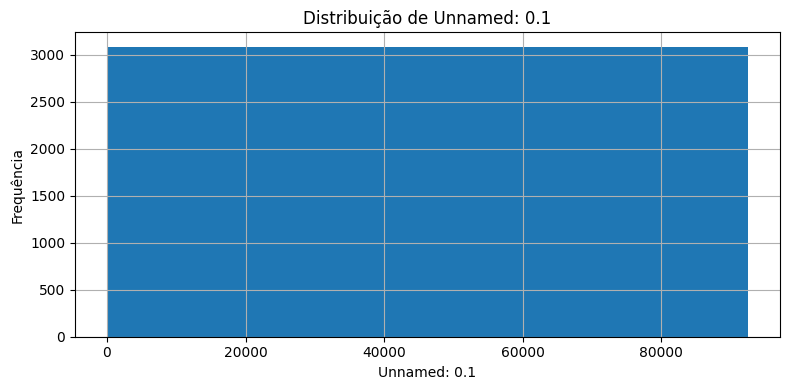

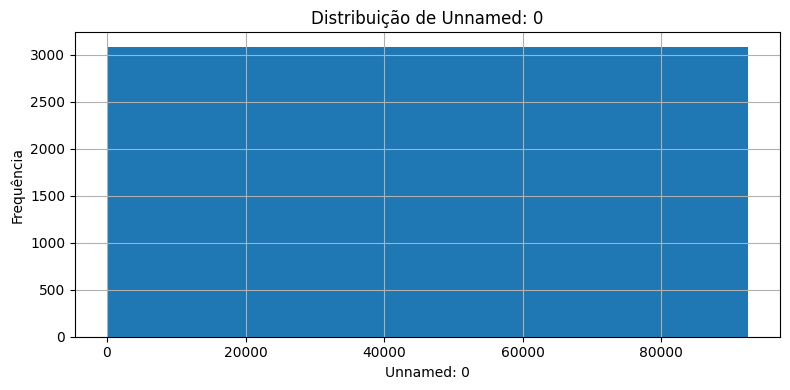

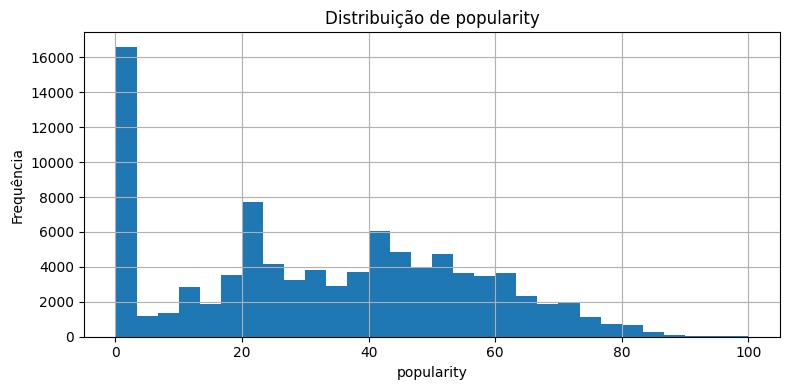

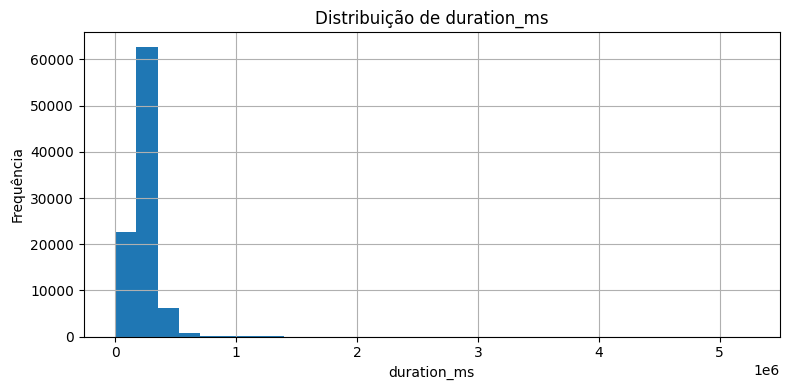

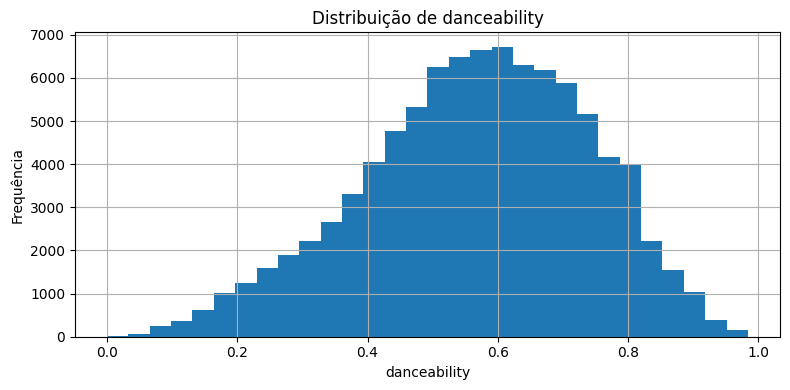

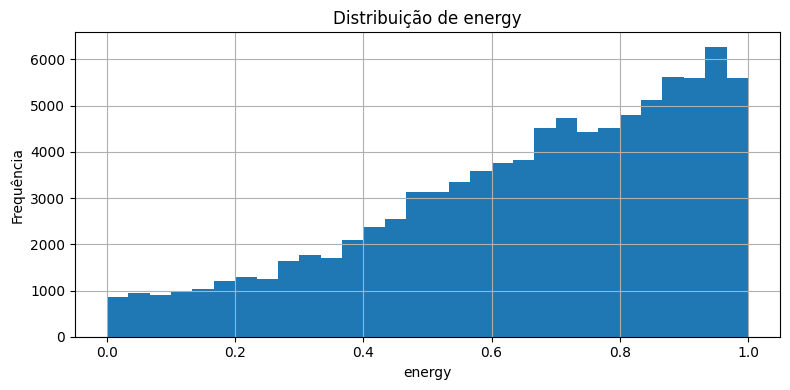

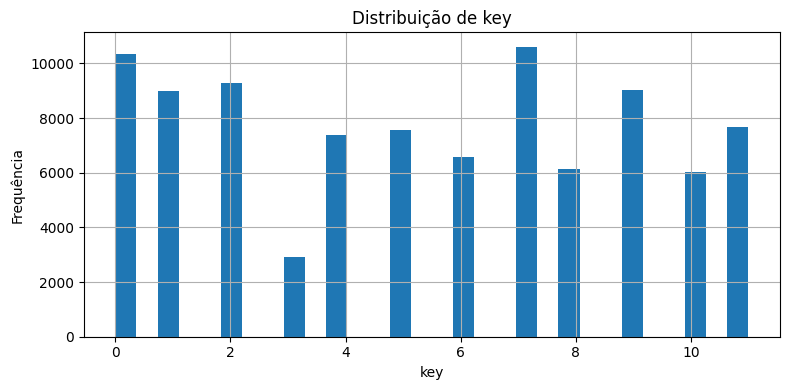

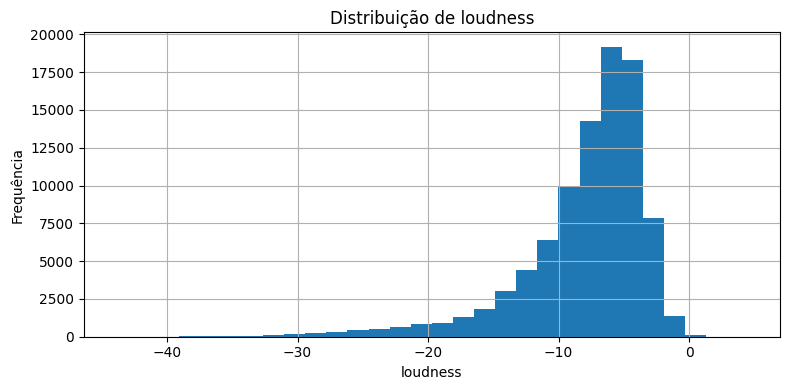

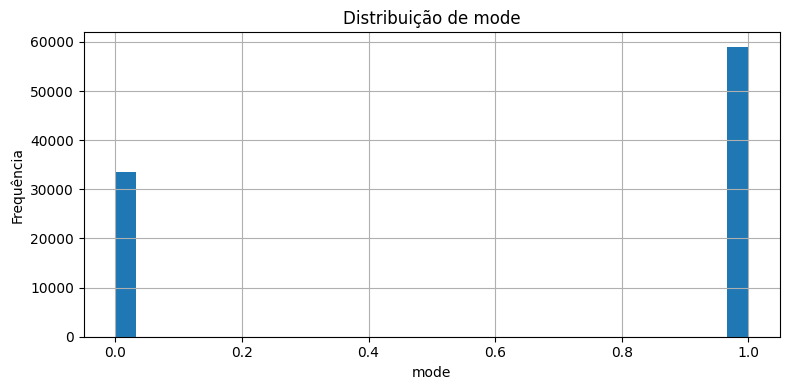

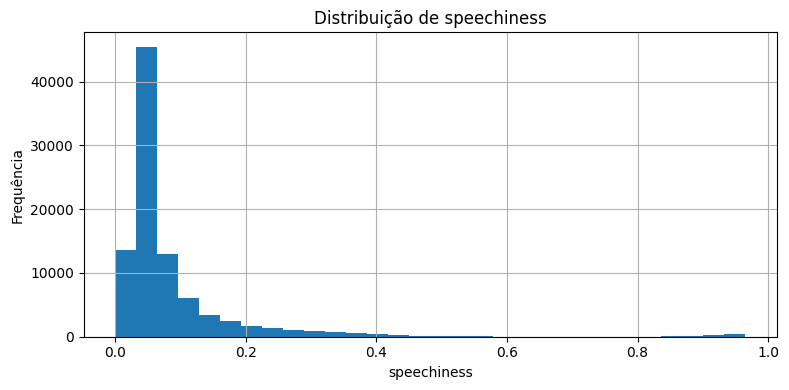

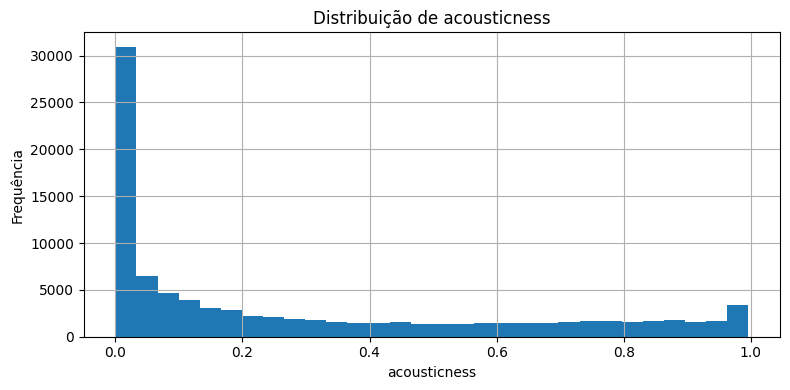

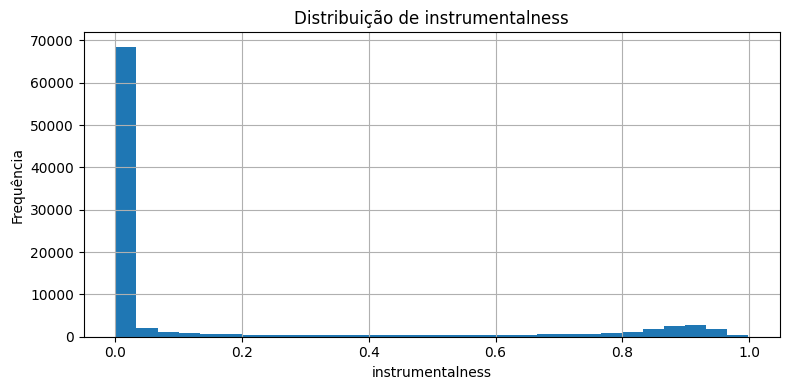

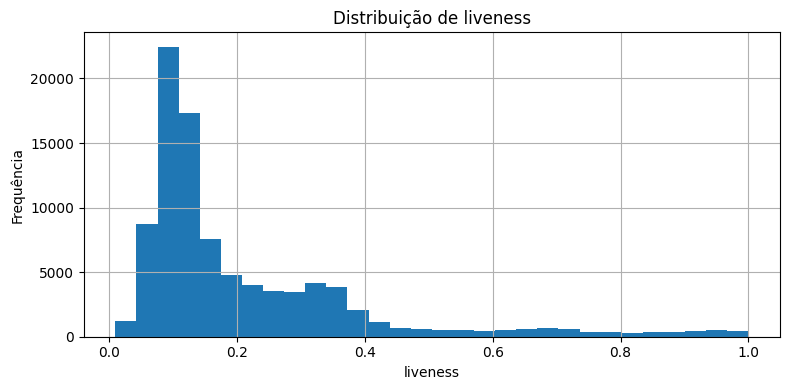

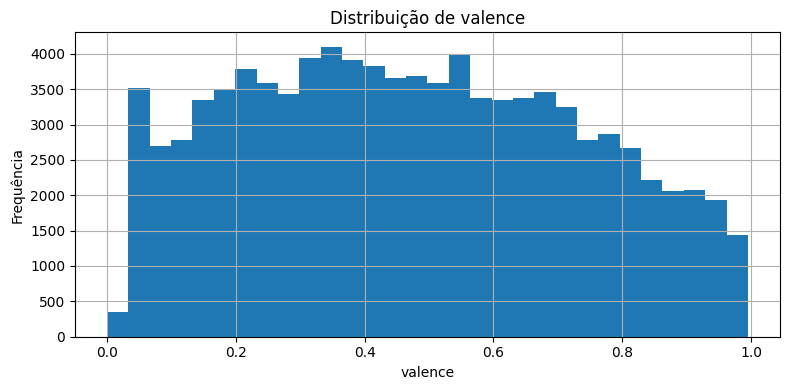

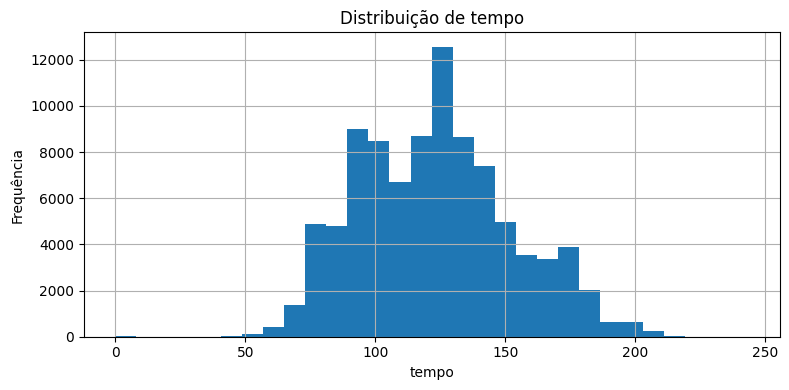

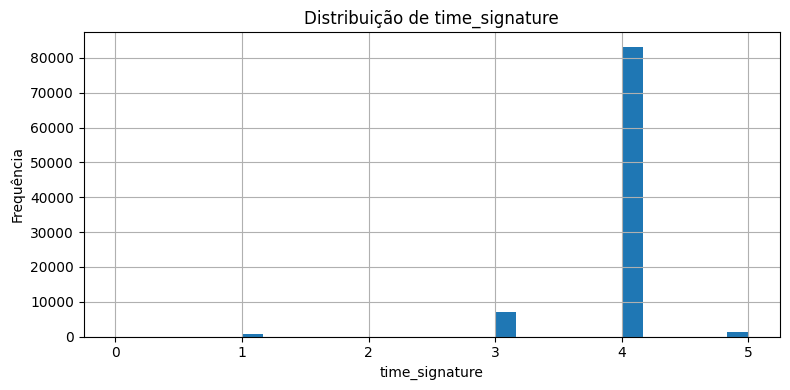

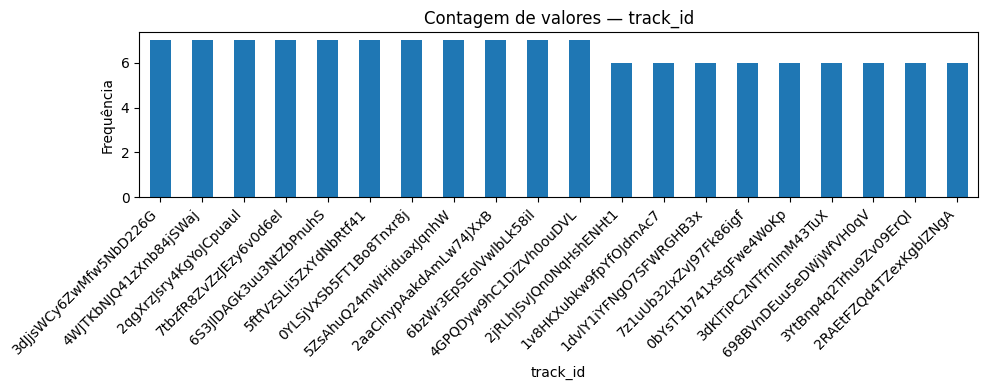

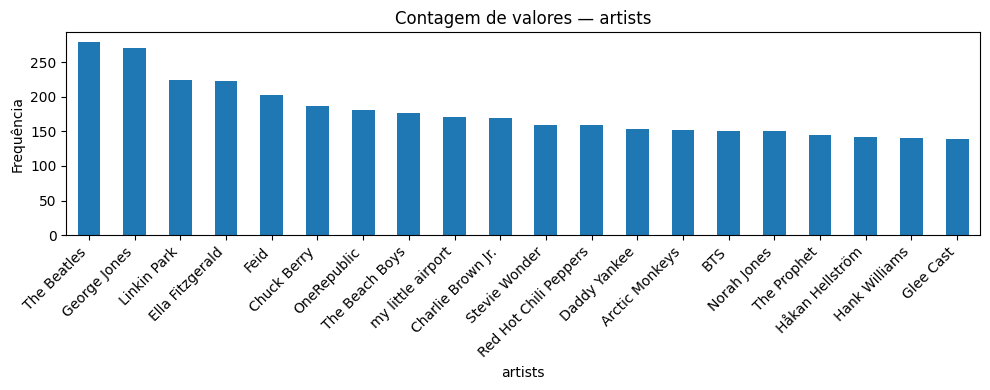

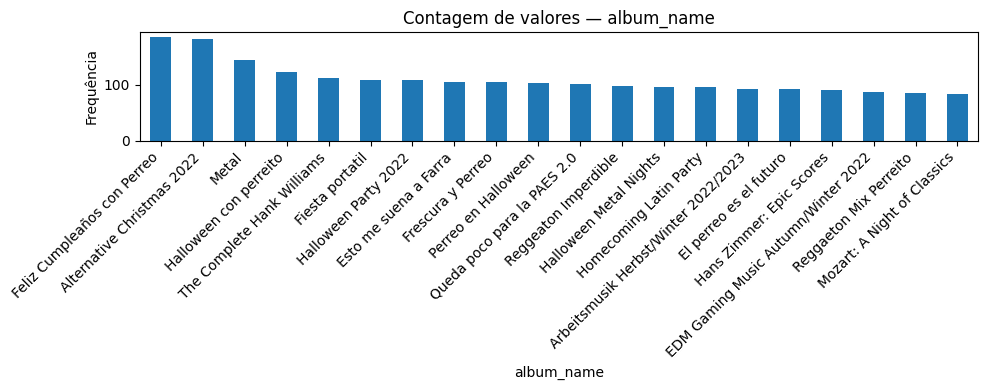

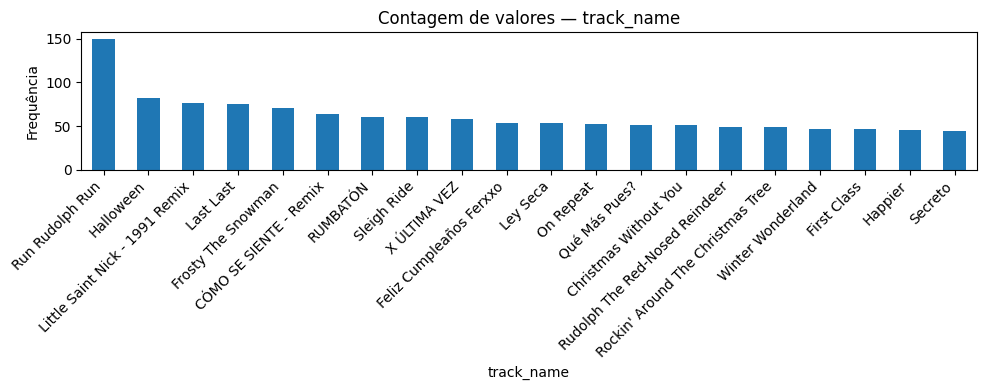

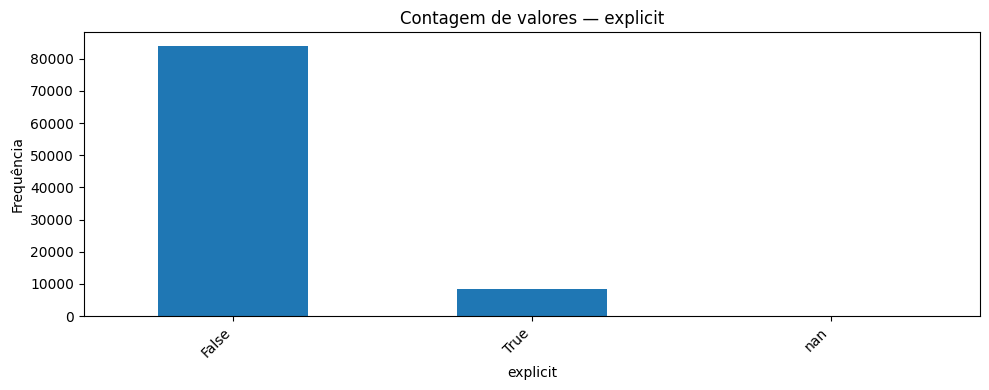

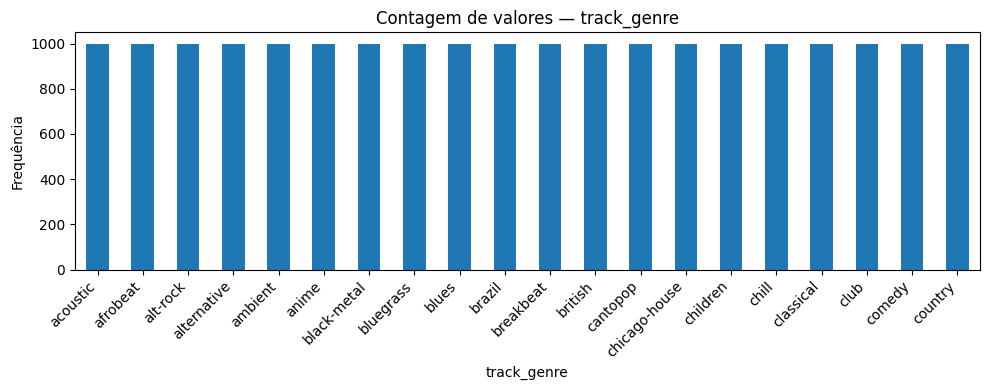

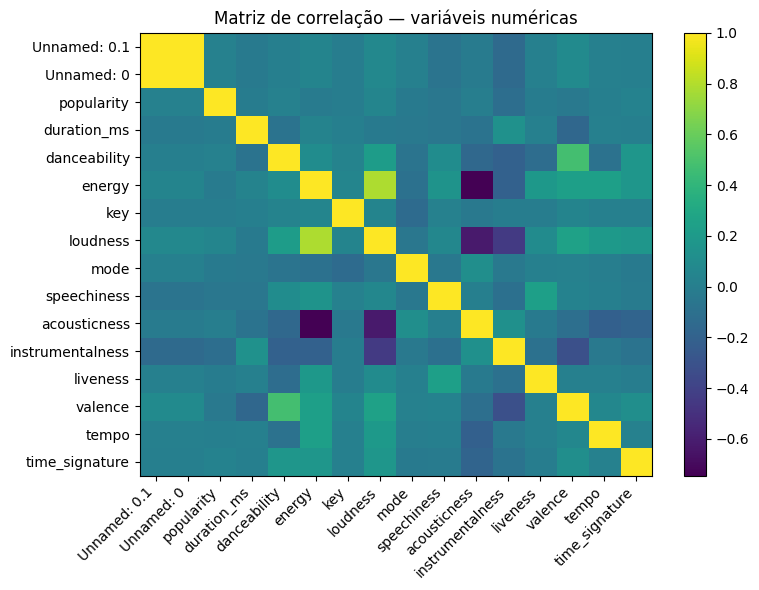

In [8]:
# Visualizações exploratórias básicas
# O grupo deve adaptar as colunas às características do dataset.

def plot_distribuicao_numerica(df: pd.DataFrame, coluna: str) -> None:
    plt.figure(figsize=(8, 4))
    df[coluna].dropna().hist(bins=30)
    plt.title(f"Distribuição de {coluna}")
    plt.xlabel(coluna)
    plt.ylabel("Frequência")
    plt.tight_layout()
    plt.show()

def plot_contagem_categorica(df: pd.DataFrame, coluna: str, top_n: int = 20) -> None:
    plt.figure(figsize=(10, 4))
    df[coluna].value_counts(dropna=False).head(top_n).plot(kind="bar")
    plt.title(f"Contagem de valores — {coluna}")
    plt.xlabel(coluna)
    plt.ylabel("Frequência")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

def plot_matriz_correlacao(df: pd.DataFrame) -> None:
    numericas = df.select_dtypes(include=np.number)

    if numericas.shape[1] < 2:
        print("Não há pelo menos duas variáveis numéricas para calcular correlação.")
        return

    corr = numericas.corr()

    plt.figure(figsize=(8, 6))
    plt.imshow(corr, aspect="auto")
    plt.colorbar()
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
    plt.yticks(range(len(corr.columns)), corr.columns)
    plt.title("Matriz de correlação — variáveis numéricas")
    plt.tight_layout()
    plt.show()

# Exemplos de uso:
nums = ['Unnamed: 0.1', 'Unnamed: 0', 'popularity', 'duration_ms', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']
cats = ['track_id', 'artists', 'album_name', 'track_name', 'explicit', 'track_genre']

[ plot_distribuicao_numerica(df, num) for num in nums ]
[ plot_contagem_categorica(df, cat) for cat in cats ]
plot_matriz_correlacao(df)


## 2.2 Análise visual — interpretação

Os gráficos confirmam que as variáveis acústicas constituem uma base rica para o agrupamento, mas também revelam características estatísticas que exigem tratamento cuidadoso. `danceability`, `valence` e `tempo` apresentam distribuições relativamente contínuas e bem espalhadas, o que favorece a formação de clusters gradativos e semanticamente interpretáveis. `instrumentalness` mostra um padrão particularmente informativo: há forte concentração próxima de zero e um segundo grupo menor concentrado em valores altos (próximos de 0,8–1,0), sugerindo uma separação natural entre músicas predominantemente vocais e faixas instrumentais. `speechiness`, `liveness` e `acousticness` também são bastante assimétricas, com concentração em valores baixos e caudas longas, indicando que determinadas características são raras, mas potencialmente muito discriminativas. Esses padrões são relevantes porque atributos com distribuições não uniformes frequentemente capturam estruturas latentes importantes no espaço de características.

Os gráficos também evidenciam a presença de valores extremos e de variáveis com baixa capacidade discriminativa. `duration_ms` possui forte assimetria à direita e poucos registros muito longos, confirmando a existência de outliers que podem distorcer algoritmos baseados em distância. `loudness` apresenta cauda à esquerda, com algumas músicas muito mais silenciosas que a maioria. Em contraste, `mode` e `time_signature` estão fortemente concentrados em poucos valores — especialmente `time_signature = 4`, que domina amplamente o conjunto. Isso sugere que tais variáveis oferecem pouca informação adicional para o agrupamento e podem até introduzir ruído se tratadas como contínuas. A matriz de correlação reforça essa interpretação ao mostrar relações moderadas a fortes entre `energy` e `loudness` (positiva), `energy` e `acousticness` (negativa) e `danceability` e `valence` (positiva). Essas correlações indicam redundância parcial entre atributos, o que pode justificar técnicas como análise de componentes principais (PCA) ou, ao menos, uma seleção criteriosa de variáveis.

Nas variáveis categóricas, `explicit` apresenta forte desbalanceamento, com predominância expressiva de músicas não explícitas, enquanto `track_genre` mostra uma distribuição artificialmente balanceada, com aproximadamente 1.000 músicas por gênero. Esse equilíbrio é importante porque reduz o risco de alguns gêneros dominarem a estrutura global do dataset e facilita a avaliação externa dos clusters encontrados. Em contrapartida, `track_id`, `artists`, `album_name` e `track_name` mantêm alta cardinalidade e funcionam essencialmente como identificadores ou descritores específicos, sem utilidade direta para clustering. Sua exclusão é recomendada tanto para evitar aumento desnecessário da dimensionalidade quanto para reduzir o custo computacional.

Essas observações têm implicações claras para as diretrizes de IA responsável adotadas no projeto. Do ponto de vista de Eficiência e Escalabilidade, a identificação de atributos redundantes, altamente correlacionados ou pouco informativos permite reduzir dimensionalidade e acelerar algoritmos de agrupamento, tornando o processo mais eficiente em um dataset com mais de 92 mil registros. A presença de outliers e distribuições muito assimétricas também sinaliza a necessidade de padronização e eventual tratamento de extremos para evitar instabilidades numéricas. Sob a perspectiva de Usabilidade e Acessibilidade, os padrões observados sugerem que os clusters poderão ser interpretados em termos musicais intuitivos, como “faixas instrumentais”, “músicas acústicas”, “canções energéticas” ou “faixas dançantes”. Além disso, o balanceamento de `track_genre` e o uso de variáveis acústicas com significado semântico claro tornam os resultados mais fáceis de explicar e validar por usuários não especialistas.



In [10]:
# Detecção simples de outliers em variáveis numéricas usando IQR
# Esta função é um exemplo. O grupo deve avaliar se o critério faz sentido para cada atributo.

def detectar_outliers_iqr(df: pd.DataFrame, coluna: str) -> pd.DataFrame:
    serie = df[coluna].dropna()

    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    outliers = df[(df[coluna] < limite_inferior) | (df[coluna] > limite_superior)]

    print(f"Coluna: {coluna}")
    print(f"Q1: {q1}")
    print(f"Q3: {q3}")
    print(f"IQR: {iqr}")
    print(f"Limite inferior: {limite_inferior}")
    print(f"Limite superior: {limite_superior}")
    print(f"Número de outliers: {len(outliers)}")

    return outliers

# Exemplo de uso:
[ display(detectar_outliers_iqr(df, num).head()) for num in nums ]


Coluna: Unnamed: 0.1
Q1: 23130.0
Q3: 69392.0
IQR: 46262.0
Limite inferior: -46263.0
Limite superior: 138785.0
Número de outliers: 0


,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre


Coluna: Unnamed: 0
Q1: 23130.75
Q3: 69392.25
IQR: 46261.5
Limite inferior: -46261.5
Limite superior: 138784.5
Número de outliers: 0


,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre


Coluna: popularity
Q1: 16.0
Q3: 51.0
IQR: 35.0
Limite inferior: -36.5
Limite superior: 103.5
Número de outliers: 0


...

Coluna: tempo
Q1: 99.986
Q3: 140.942
IQR: 40.956
Limite inferior: 38.552
Limite superior: 202.376
Número de outliers: 326


,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
384,384,384.0,63wsZUhUZLlh1OsyrZq7sz,Boyce Avenue;Kina Grannis,"Cover Sessions, Vol. 2",Fast Car,61.0,304293.0,False,0.392,...,-9.845,1.0,0.0363,0.807,0.0,0.0797,0.508,204.961,4.0,acoustic
519,519,519.0,6cMzeng5QA8fd2qqiMeIyg,Jonah Baker,Running Up That Hill (A Deal With God) [Acoustic],Running Up That Hill (A Deal With God) - Acoustic,51.0,168042.0,False,0.385,...,-14.672,0.0,0.0476,0.899,0.0,0.1130,0.427,203.816,4.0,acoustic
561,561,561.0,2dMkrhsWFVP2rHZmTEKkeh,Mat Kearney,CRAZYTALK,Wanted Man,59.0,235106.0,False,0.514,...,-8.978,1.0,0.0941,0.805,0.0,0.2110,0.677,203.651,4.0,acoustic
864,864,864.0,2vLHinYk689HDnLkrsCZGF,Erato;Charlotte Almgren,As Long as You Love Me,As Long as You Love Me,54.0,151618.0,False,0.404,...,-12.463,0.0,0.0604,0.891,0.0,0.1030,0.298,202.996,4.0,acoustic
973,973,973.0,0Stf1ND7zaL3TEo8kZgld1,Son&Dad;Filip Nordin,Acustic Covers of Popular Songs,I Want It That Way - Acoustic Covers of Popula...,51.0,136470.0,False,0.392,...,-6.563,0.0,0.0354,0.746,0.0,0.3210,0.368,203.571,4.0,acoustic


Coluna: time_signature
Q1: 4.0
Q3: 4.0
IQR: 0.0
Limite inferior: 4.0
Limite superior: 4.0
Número de outliers: 9369


,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
3,3,3.0,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71.0,201933.0,False,0.266,...,-18.515,1.0,0.0363,0.905,0.000071,0.1320,0.1430,181.740,3.0,acoustic
6,6,6.0,6Vc5wAMmXdKIAM7WUoEb7N,A Great Big World;Christina Aguilera,Is There Anybody Out There?,Say Something,74.0,229400.0,False,0.407,...,-8.822,1.0,0.0355,0.857,0.000003,0.0913,0.0765,141.284,3.0,acoustic
11,11,11.0,5ivF4eQBqJiVL5IAE9jRyl,Jason Mraz,Love Is a Four Letter Word,I Won't Give Up,69.0,240165.0,False,0.483,...,-10.058,1.0,0.0429,0.694,0.000000,0.1150,0.1390,133.406,3.0,acoustic
15,15,15.0,1KHdq8NK9QxnGjdXb55NiG,Landon Pigg,The Boy Who Never,Falling in Love at a Coffee Shop,58.0,244986.0,False,0.489,...,-7.933,1.0,0.0274,0.200,0.000046,0.1790,0.2380,83.457,3.0,acoustic
22,22,22.0,5TvE3pk05pyFIGdSY9j4DJ,A Great Big World;Christina Aguilera,Is There Anybody Out There? - Track by Track C...,Say Something,70.0,229400.0,False,0.407,...,-8.822,1.0,0.0355,0.857,0.000003,0.0913,0.0765,141.284,3.0,acoustic


[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]

## 2.3 Problemas de qualidade dos dados

| Problema identificado                                                                          | Evidência                                                                                                                                                                    |
| ---------------------------------------------------------------------------------------------- | ---------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| Valores ausentes em `artists`, `album_name` e `track_name`                                     | Estatísticas descritivas mostraram `count = 92.523` nessas colunas, contra 92.524 registros totais, indicando apenas 1 valor ausente em cada uma                             |
| Duplicatas                                                                                     | `track_id` possui 73.397 valores únicos para 92.524 registros, evidenciando que diversas músicas aparecem repetidas no dataset                                               |
| Outliers em `duration_ms`, `loudness`, `speechiness`, `instrumentalness`, `liveness` e `tempo` | Método do IQR identificou 4.621 outliers em `duration_ms`, 5.275 em `loudness`, 10.673 em `speechiness`, 20.393 em `instrumentalness`, 6.456 em `liveness` e 326 em `tempo`  |
| Categorias raras                                                                               | `explicit = True` representa uma minoria do conjunto, enquanto `track_genre` está balanceado com aproximadamente 1.000 músicas por gênero                                    |
| Atributos sensíveis ou identificadores                                                         | `track_id` é um identificador quase único; `track_name`, `album_name` e `artists` possuem alta cardinalidade; `Unnamed: 0` e `Unnamed: 0.1` são índices artificiais          |

<br><br>


| Problema identificado                                                                          | Decisão tomada                                   |
| ---------------------------------------------------------------------------------------------- | ------------------------------------------------ |
| Valores ausentes em `artists`, `album_name` e `track_name`                                     | Remover registros ausentes                       |
| Duplicatas                                                                                     | Remover duplicatas com base em `track_id`        |
| Outliers em `duration_ms`, `loudness`, `speechiness`, `instrumentalness`, `liveness` e `tempo` | Manter os valores e aplicar padronização robusta |
| Categorias raras                                                                               | Não realizar tratamento específico               |
| Atributos sensíveis ou identificadores                                                         | Remover essas colunas                            |

<br><br>

### Observação sobre responsabilidade

As decisões de preparação têm implicações diretas para as diretrizes de IA responsável adotadas no projeto. A remoção de identificadores e colunas irrelevantes reduz a dimensionalidade e melhora a Eficiência e Escalabilidade, diminuindo o tempo de processamento e o consumo de memória em um dataset com mais de 92 mil registros. A opção por manter outliers semanticamente significativos preserva perfis musicais legítimos, evitando perda de diversidade e favorecendo a formação de clusters mais representativos. Por fim, a utilização exclusiva de atributos acústicos interpretáveis, como `danceability`, `energy` e `instrumentalness`, contribui para a Usabilidade e Acessibilidade, pois permite explicar os agrupamentos em termos musicais intuitivos e facilmente compreensíveis por usuários não especialistas.


In [12]:
# Exemplo de preparação dos dados
# Esta célula é propositalmente genérica.
# O grupo deve adaptar de acordo com o dataset e a tarefa.

def preparar_dados_basico(
    df: pd.DataFrame,
    colunas_remover=None,
    imputar_numericas=True,
    imputar_categoricas=True
) -> pd.DataFrame:
    df_prep = df.copy()

    df_prep = df_prep.drop_duplicates()

    if "track_id" in df_prep.columns:
        df_prep = df_prep.drop_duplicates(subset=["track_id"])

    if colunas_remover is None:
        colunas_remover = [
            "Unnamed: 0.1",
            "Unnamed: 0",
            "track_id",
            "track_name",
            "album_name",
            "artists",
            "explicit",
            "track_genre",
        ]

    colunas_existentes = [col for col in colunas_remover if col in df_prep.columns]
    df_prep = df_prep.drop(columns=colunas_existentes)

    if imputar_numericas:
        for col in df_prep.select_dtypes(include=np.number).columns:
            df_prep[col] = df_prep[col].fillna(df_prep[col].median())

    if imputar_categoricas:
        for col in df_prep.select_dtypes(include=["object", "category"]).columns:
            df_prep[col] = df_prep[col].fillna("desconhecido")

    return df_prep


df_prep = preparar_dados_basico(df)
display(df_prep.head())


,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
0,73.0,230666.0,0.676,0.4610,1.0,-6.746,0.0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4.0
1,55.0,149610.0,0.420,0.1660,1.0,-17.235,1.0,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4.0
2,57.0,210826.0,0.438,0.3590,0.0,-9.734,1.0,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4.0
3,71.0,201933.0,0.266,0.0596,0.0,-18.515,1.0,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3.0
4,82.0,198853.0,0.618,0.4430,2.0,-9.681,1.0,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4.0


## 2.4 Justificativa da preparação dos dados

A preparação removeu as colunas `Unnamed: 0.1` e `Unnamed: 0`, pois elas são índices artificiais gerados em exportações anteriores do arquivo e não representam características musicais. Também foram removidas `track_id`, `track_name`, `album_name` e `artists`, porque funcionam como identificadores ou metadados textuais de alta cardinalidade, sem utilidade direta para medir similaridade acústica. As colunas `explicit` e `track_genre` também foram retiradas dos atributos de entrada: `explicit` descreve um metadado editorial, não uma propriedade sonora, e `track_genre` deve ser preservada apenas para avaliação externa dos grupos, não para formar os clusters.

As duplicatas exatas foram removidas inicialmente e, em seguida, também foram eliminadas duplicatas com base em `track_id`, quando essa coluna estava presente. Essa decisão evita que a mesma música apareça mais de uma vez no espaço de agrupamento e receba peso artificialmente maior na formação dos clusters. Os valores ausentes remanescentes nas variáveis numéricas foram preenchidos pela mediana, por ser uma medida mais robusta a valores extremos do que a média. Valores ausentes em variáveis categóricas, caso ainda existam após a remoção das colunas textuais, foram preenchidos com `"desconhecido"`, preservando o registro sem inventar uma categoria específica.

Não foi aplicada normalização, discretização ou codificação nessa função básica. Isso significa que a função apenas realiza limpeza inicial, e não a preparação completa para o clustering. Para algoritmos baseados em distância, como K-Means, ainda será necessário aplicar normalização ou padronização posteriormente, pois variáveis como `duration_ms`, `tempo`, `loudness` e atributos entre 0 e 1 estão em escalas muito diferentes. Também não houve remoção de outliers. Essa escolha foi deliberada: valores extremos em `duration_ms`, `instrumentalness`, `speechiness`, `liveness`, `tempo` e `loudness` podem representar músicas reais com características específicas, como faixas longas, instrumentais, ao vivo ou muito faladas. Removê-los automaticamente poderia eliminar padrões musicais relevantes.

Essas decisões introduzem alguns riscos. A remoção de `artists`, `album_name` e `track_name` impede análises baseadas em contexto cultural, autoria ou popularidade de artistas, mas isso é aceitável porque a tarefa definida é segmentar músicas por similaridade de áudio. A remoção de `track_genre` evita vazamento de informação, mas reduz a informação disponível durante o agrupamento; por isso, ela deve ser mantida separadamente para avaliação. A não remoção de outliers preserva diversidade musical, mas pode afetar algoritmos sensíveis a distância, exigindo padronização robusta na etapa seguinte. Em relação às diretrizes escolhidas, a preparação melhora Eficiência e Escalabilidade ao reduzir dimensionalidade, remover identificadores e evitar metadados de alta cardinalidade. Também favorece Usabilidade e Acessibilidade, pois mantém atributos acústicos interpretáveis, permitindo explicar os clusters em termos compreensíveis, como músicas mais dançantes, acústicas, instrumentais, energéticas ou faladas.



## 2.5 Interações com LLM — Data Understanding & Data Preparation

### Subtarefa comparável

Nesta etapa, as duas trilhas devem receber a mesma subtarefa geral.

**Subtarefa escolhida:** propor estratégias de limpeza, transformação e preparação dos dados para a tarefa de mineração

---

### Trilha A — baseline

**Modelo utilizado:** ChatGPT 5.5-Instant
**Data de acesso:** 20/05/2026
**Link da conversa:** https://chatgpt.com/share/6a0daf90-a374-83e9-8491-33d7158ec569

#### Prompt principal — baseline

```text
Tenho um dataset do spotify (https://www.kaggle.com/datasets/yashdev01/spotify-tracks-dataset) com as seguintes colunas: Colunas numéricas: ['Unnamed: 0.1', 'Unnamed: 0', 'popularity', 'duration_ms', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature'] Colunas não numéricas: ['track_id', 'artists', 'album_name', 'track_name', 'explicit', 'track_genre']A tarefa de mineração é agrupamento (Clustering) para segmentar músicas por similaridade de áudio. Sugira uma estratégia de Data Understanding e Data Preparation para preparar os dados para essa tarefa.
```

#### Síntese da resposta da LLM

Para a tarefa de agrupamento (clustering) com o objetivo de segmentar músicas por similaridade de características acústicas, a estratégia de Data Understanding e Data Preparation deve priorizar atributos que representem propriedades sonoras mensuráveis e eliminar variáveis puramente identificadoras ou descritivas. Como o clustering é uma técnica não supervisionada baseada em distância ou densidade, a qualidade dos grupos dependerá diretamente da escolha adequada dos atributos, da padronização das escalas e da remoção de informações irrelevantes.

No Data Understanding, o primeiro passo é compreender a natureza de cada variável. O dataset contém atributos de identificação, metadados textuais e variáveis numéricas de áudio fornecidas pela API do Spotify. As colunas `track_id`, `track_name`, `album_name` e `artists` são essencialmente identificadores ou descrições textuais; embora sejam úteis para interpretação posterior dos clusters, não devem ser usadas diretamente na formação dos grupos, pois não expressam características acústicas. A coluna `track_genre` é um rótulo categórico já existente e pode servir como referência para avaliar qualitativamente os clusters obtidos, mas não deve ser utilizada como entrada, pois isso introduziria uma informação externa que poderia enviesar artificialmente o agrupamento. As colunas `Unnamed: 0` e `Unnamed: 0.1` são índices residuais gerados durante exportações anteriores e devem ser descartadas, pois não possuem significado analítico.

As variáveis mais relevantes para a tarefa são aquelas que descrevem diretamente o conteúdo sonoro da música: `danceability`, `energy`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence`, `tempo`, `loudness`, `duration_ms`, `key`, `mode`, `time_signature` e `popularity`. Entre elas, as variáveis contínuas normalizadas entre 0 e 1 (`danceability`, `energy`, `acousticness`, etc.) possuem forte poder discriminativo. `Tempo`, `loudness` e `duration_ms` apresentam escalas distintas e requerem padronização. `Popularity` não é uma característica acústica propriamente dita, mas pode refletir aspectos de produção musical e recepção do público; sua inclusão é opcional e deve ser justificada. Já `key`, `mode` e `time_signature` representam propriedades musicais discretas. Embora possam contribuir para a segmentação, devem ser tratadas com cautela, pois seus valores numéricos não possuem relação ordinal natural.

A análise exploratória deve investigar valores ausentes, duplicatas e distribuições. É importante verificar se existem músicas repetidas, o que pode ocorrer quando diferentes versões ou duplicações de registros foram mantidas no dataset. Duplicatas exatas devem ser removidas. Também é recomendável analisar a distribuição das variáveis para identificar concentrações extremas, como o grande número de faixas com `instrumentalness` próximo de zero ou `speechiness` muito baixo. Tais padrões são esperados e não necessariamente representam problemas. Outliers devem ser avaliados com cautela, pois, em clustering, pontos extremos frequentemente correspondem a estilos musicais legítimos e distintivos, como música ambiente, podcasts ou faixas experimentais.

Na etapa de Data Preparation, o primeiro procedimento é remover as colunas `Unnamed: 0`, `Unnamed: 0.1`, `track_id`, `track_name`, `album_name`, `artists` e `track_genre`. Em seguida, deve-se verificar a existência de valores ausentes. Caso sejam poucos, pode-se remover as linhas correspondentes. Caso sejam mais numerosos, a imputação pela mediana é a estratégia mais adequada para atributos numéricos, pois preserva robustez frente a distribuições assimétricas. Como o dataset do Spotify costuma ser relativamente limpo, espera-se que a perda de registros seja pequena.

O tratamento das variáveis `key`, `mode` e `time_signature` exige uma decisão metodológica importante. Numericamente, esses atributos representam categorias musicais e não magnitudes. Uma abordagem conservadora consiste em mantê-los como variáveis numéricas discretas, desde que devidamente padronizadas, aceitando que a distância euclidiana interpretará diferenças aritméticas entre categorias. Uma abordagem mais rigorosa seria aplicar codificação one-hot, especialmente para `key`, cuja natureza circular torna inadequada a interpretação linear. Contudo, essa codificação aumenta a dimensionalidade e pode reduzir a eficiência computacional. Em aplicações acadêmicas introdutórias, ambas as abordagens são defensáveis, desde que a escolha seja explicitamente documentada.

Após a seleção dos atributos, é indispensável realizar normalização ou padronização. Como algoritmos de clustering como K-means clustering e Hierarchical clustering dependem de métricas de distância, atributos em escalas maiores dominariam o processo caso não fossem transformados. A padronização com scikit-learn `StandardScaler`, que centraliza cada variável em média zero e desvio padrão unitário, é a escolha mais apropriada. Isso coloca `tempo`, `loudness`, `duration_ms` e as variáveis já limitadas entre 0 e 1 em uma escala comparável.

Opcionalmente, pode-se aplicar técnicas de redução de dimensionalidade, como Principal Component Analysis (PCA), para eliminar redundâncias e facilitar visualização dos clusters. Isso é particularmente útil porque várias características do Spotify são correlacionadas, como `energy` e `loudness`, ou `acousticness` e `instrumentalness`. Entretanto, o clustering também pode ser executado diretamente no conjunto padronizado, utilizando PCA apenas para fins de análise visual.

Em relação aos riscos metodológicos, a exclusão de metadados textuais impede que informações semânticas, como artista ou álbum, influenciem os clusters, o que é desejável para uma segmentação puramente baseada em áudio. Por outro lado, essa decisão pode ignorar contextos musicais relevantes, como estilo autoral ou período de lançamento. A inclusão de `popularity` pode introduzir viés comercial, agrupando músicas por sucesso de mercado e não por semelhança sonora. A padronização assume que todas as variáveis têm importância semelhante, o que pode não refletir a realidade musical. Além disso, a eventual remoção de outliers pode eliminar precisamente faixas que representam nichos ou gêneros distintos, reduzindo a diversidade dos agrupamentos.

Uma estratégia final recomendada consiste em utilizar as seguintes variáveis de entrada: `danceability`, `energy`, `loudness`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence`, `tempo`, `duration_ms`, e opcionalmente `key`, `mode`, `time_signature` e `popularity`. Após remoção de duplicatas, tratamento de valores ausentes e padronização com `StandardScaler`, o conjunto estará adequadamente preparado para aplicação de algoritmos de clustering. Os clusters resultantes poderão então ser interpretados com apoio das colunas textuais removidas e comparados qualitativamente com `track_genre`, permitindo verificar se grupos acústicos correspondem a estilos musicais reconhecidos.


---

### Trilha B — guiada por diretrizes

**Modelo utilizado:** ChatGPT 5.5-Instant
**Data de acesso:** 20/05/2026
**Link da conversa:** https://chatgpt.com/share/6a0db005-57d8-83e9-88e0-5bc7332732f9

#### Prompt principal — guiado

```text
Tenho um dataset do spotify (https://www.kaggle.com/datasets/yashdev01/spotify-tracks-dataset) com as seguintes colunas: Colunas numéricas: ['Unnamed: 0.1', 'Unnamed: 0', 'popularity', 'duration_ms', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature'] Colunas não numéricas: ['track_id', 'artists', 'album_name', 'track_name', 'explicit', 'track_genre']A tarefa de mineração é agrupamento (Clustering) para segmentar músicas por similaridade de áudio. Sugira uma estratégia de Data Understanding e Data Preparation para preparar os dados para essa tarefa. Considere explicitamente as diretrizes: 1. eficiencia & escalabilidade 2. usabilidade & acessibilidade Ao sugerir a preparação, indique: - possíveis atributos sensíveis, se houver; - riscos de viés ou perda de informação; - decisões que devem ser documentadas; - transformações necessárias; - limitações e trade-offs.
```

#### Síntese da resposta da LLM

Para a tarefa de agrupamento (clustering) de músicas do Spotify, o objetivo é representar cada faixa por um conjunto de atributos que capturem suas características sonoras de forma comparável. Como o clustering é um método não supervisionado, a qualidade dos grupos depende diretamente da escolha e preparação das variáveis. Nesse contexto, o foco deve estar em atributos de áudio que reflitam propriedades musicais mensuráveis, como energia, dançabilidade, acústica e tempo, e não em identificadores ou metadados textuais.

No que se refere ao Data Understanding, a primeira etapa consiste em compreender o significado de cada atributo. O dataset contém variáveis numéricas de natureza heterogênea. Algumas representam características contínuas já normalizadas entre 0 e 1, como `danceability`, `energy`, `speechiness`, `acousticness`, `instrumentalness`, `liveness` e `valence`. Outras representam medidas em escalas distintas, como `duration_ms`, `tempo`, `loudness` e `popularity`. Há também variáveis discretas e categóricas codificadas numericamente, como `key` (tom musical), `mode` (maior ou menor) e `time_signature` (compasso). Além disso, o dataset inclui colunas textuais como `artists`, `album_name`, `track_name` e `track_genre`, e identificadores únicos como `track_id` e as colunas `Unnamed: 0` e `Unnamed: 0.1`, que normalmente são índices residuais de exportação.

Para clustering por similaridade de áudio, as colunas mais relevantes são as chamadas features acústicas extraídas automaticamente pelo Spotify. O conjunto principal de atributos recomendado é: `duration_ms`, `danceability`, `energy`, `loudness`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence`, `tempo`, `key`, `mode` e `time_signature`. A variável `popularity` merece atenção especial. Embora seja numérica, ela não descreve propriedades acústicas da música, mas sim seu desempenho comercial e histórico de consumo. Sua inclusão pode fazer com que músicas sejam agrupadas por sucesso e não por similaridade sonora. Assim, para uma segmentação estritamente musical, o mais adequado é removê-la ou, alternativamente, testar sua influência em análises comparativas.

As colunas `track_id`, `track_name`, `album_name` e `artists` devem ser removidas, pois funcionam apenas como identificadores ou descrições textuais. Se mantidas, exigiriam técnicas de codificação de alta dimensionalidade, aumentando significativamente o custo computacional e desviando o objetivo da análise. A coluna `track_genre`, embora não deva ser usada como entrada no clustering, é extremamente útil para interpretação posterior dos grupos. Após a formação dos clusters, ela pode servir como referência externa para avaliar se determinados agrupamentos correspondem a gêneros musicais conhecidos.

Quanto à identificação de atributos sensíveis, este dataset não contém informações pessoais diretamente associadas a indivíduos, como idade, sexo ou localização. Contudo, `popularity` pode refletir preferências coletivas do público e influências da indústria musical, introduzindo vieses de mercado. `track_genre` também pode carregar classificações subjetivas e simplificadas. Embora não sejam atributos sensíveis em sentido estrito, ambos podem induzir interpretações enviesadas e devem ser tratados com cautela.

No Data Preparation, a primeira transformação consiste na remoção de colunas irrelevantes: `Unnamed: 0`, `Unnamed: 0.1`, `track_id`, `track_name`, `album_name`, `artists` e, opcionalmente, `popularity`. Em seguida, devem ser verificadas duplicatas. O ideal é remover registros com `track_id` repetido ou duplicatas exatas, pois músicas repetidas podem distorcer a densidade do espaço e influenciar algoritmos como K-Means e DBSCAN.

O tratamento de valores ausentes deve ser documentado cuidadosamente. Se a quantidade de valores faltantes for pequena, pode-se remover os registros incompletos sem impacto significativo. Caso contrário, recomenda-se imputação pela mediana para variáveis numéricas, pois ela é robusta à presença de outliers. Essa decisão preserva a escalabilidade e evita a exclusão excessiva de observações.

A detecção e tratamento de outliers também é relevante. Músicas com durações extremamente longas, tempos muito altos ou valores incomuns de loudness podem influenciar fortemente algoritmos baseados em distância. Uma abordagem prudente é aplicar o método do intervalo interquartil (IQR) ou winsorização, limitando valores extremos aos percentis 1 e 99. Em vez de eliminar registros indiscriminadamente, essa estratégia preserva músicas raras, como composições experimentais ou clássicas extensas, reduzindo o risco de perda indevida de informação.

A normalização é uma etapa indispensável. Como `duration_ms` pode atingir milhões, `tempo` geralmente varia entre dezenas e centenas, e outras variáveis já estão em [0,1], algoritmos baseados em distância Euclidiana seriam dominados por atributos de maior magnitude. O procedimento recomendado é a padronização com `StandardScaler`, que transforma cada variável para média zero e desvio padrão unitário. Em cenários com muitos outliers, `RobustScaler` pode ser mais apropriado.

As variáveis `key`, `mode` e `time_signature` exigem reflexão. Apesar de representadas numericamente, elas possuem natureza categórica ou cíclica. `mode` é binária e pode ser mantida sem alterações. `time_signature` assume poucos valores discretos e, em geral, pode ser mantida como atributo ordinal simplificado. Já `key`, por representar classes circulares de tons musicais, não possui relação linear direta entre seus valores inteiros. Uma alternativa mais rigorosa seria codificá-la por seno e cosseno, preservando sua estrutura cíclica. Contudo, para fins didáticos e por razões de eficiência, muitos trabalhos mantêm essa variável em sua forma original. Essa escolha deve ser explicitamente documentada.

Se o volume de dados for muito grande, pode ser vantajoso aplicar redução de dimensionalidade com Principal Component Analysis. O PCA reduz redundâncias entre atributos altamente correlacionados, como `energy` e `loudness`, e acelera algoritmos de clustering, atendendo à diretriz de eficiência e escalabilidade. Entretanto, essa transformação diminui a interpretabilidade, pois os componentes principais deixam de corresponder diretamente a atributos musicais conhecidos. Uma prática recomendada é realizar clustering tanto com quanto sem PCA e comparar os resultados.

Sob a perspectiva de usabilidade e acessibilidade, é fundamental que toda a preparação seja compreensível e reproduzível. Cada transformação deve ser documentada com justificativa técnica, permitindo que outros usuários entendam por que determinadas variáveis foram removidas, mantidas ou transformadas. A manutenção de `track_genre` para interpretação posterior também contribui para tornar os clusters mais facilmente explicáveis para usuários não especialistas, facilitando a comunicação dos resultados.

Os principais riscos de viés e perda de informação decorrem da exclusão de `popularity`, que remove um aspecto sociocultural importante; do tratamento de outliers, que pode descartar músicas atípicas; e da normalização, que pressupõe importância semelhante entre todos os atributos. Além disso, a manutenção simplificada de `key` e `time_signature` pode não capturar integralmente suas propriedades musicais. Esses trade-offs são aceitáveis em uma primeira abordagem, desde que claramente reconhecidos e registrados.

Em síntese, a estratégia recomendada consiste em remover identificadores e colunas irrelevantes, tratar valores ausentes, eliminar duplicatas, analisar e controlar outliers, padronizar as variáveis numéricas e, opcionalmente, aplicar PCA. O conjunto final deve conter predominantemente atributos acústicos objetivos, de modo que o algoritmo de clustering identifique grupos de músicas com comportamento sonoro semelhante. Essa abordagem equilibra rigor técnico, eficiência computacional e interpretabilidade, atendendo às diretrizes de eficiência & escalabilidade e de usabilidade & acessibilidade.



## 2.6 Comparação crítica — Data Understanding & Preparation

| Aspecto                     | Trilha A — baseline                                                                                                                                | Trilha B — guiada                                                                                                                                                  | Decisão do grupo            |
| --------------------------- | -------------------------------------------------------------------------------------------------------------------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------ | --------------------------- |
| Tratamento de nulos         | Recomenda remover registros incompletos quando houver poucos valores ausentes ou imputar pela mediana em atributos numéricos.                      | Mantém a mesma estratégia, mas enfatiza que a decisão deve ser explicitamente documentada e justificada em termos de impacto e escalabilidade.                     | ACEITAR |
| Tratamento de outliers      | Sugere avaliar outliers com cautela e, em geral, evitar remoção automática, pois podem representar estilos musicais legítimos e distintivos.       | Propõe abordagem mais estruturada, com IQR ou winsorização (percentis 1 e 99), reduzindo influência de extremos sem eliminar observações raras.                    | ACEITAR TRILHA B |
| Atributos sensíveis         | Não identifica atributos sensíveis em sentido estrito; destaca apenas possível viés associado à variável `popularity`.                             | Também conclui que não há atributos sensíveis, mas discute de forma mais explícita vieses de mercado em `popularity` e subjetividade em `track_genre`.             | ACEITAR |
| Codificação de variáveis    | Discute tratamento de `key`, `mode` e `time_signature`, sugerindo mantê-las como numéricas discretas ou aplicar one-hot, especialmente para `key`. | Aprofunda a análise e sugere codificação cíclica (seno e cosseno) para `key`, mantendo alternativas mais simples por razões de eficiência.                         | ACEITAR TRILHA A |
| Redução de dimensionalidade | Sugere PCA como etapa opcional para reduzir redundância e facilitar visualização dos clusters.                                                     | Recomenda PCA de forma mais explícita como estratégia para melhorar eficiência computacional, destacando a perda de interpretabilidade.                            | ACEITAR TRILHA B |
| Justificativa técnica       | Apresenta justificativas centradas na adequação dos atributos ao objetivo de segmentação por similaridade acústica.                                | Acrescenta relação explícita com as diretrizes de eficiência & escalabilidade e usabilidade & acessibilidade, além de maior detalhamento metodológico.             | ACEITAR TRILHA B                   |
| Riscos e limitações         | Discute viés comercial em `popularity`, possíveis perdas ao remover outliers e pressuposto de pesos iguais após padronização.                      | Amplia a análise, incluindo trade-offs entre eficiência e interpretabilidade, simplificações na representação de atributos musicais e necessidade de documentação. | ACEITAR TRILHA B                  |


### Análise crítica

A comparação entre as respostas da LLM mostra que ambas apresentaram sugestões tecnicamente adequadas para a preparação de dados voltada à tarefa de clustering, mas a segunda resposta (Trilha B — guiada) foi substancialmente mais completa, metodologicamente rigorosa e alinhada às diretrizes de IA responsável solicitadas no enunciado. Em termos gerais, a LLM identificou corretamente que a tarefa exige a seleção de atributos acústicos, a remoção de identificadores e metadados textuais, o tratamento de valores ausentes, a padronização das variáveis numéricas e a possibilidade de aplicar redução de dimensionalidade por PCA. Também foi correta ao destacar que `track_genre` deve ser preservado apenas para interpretação posterior dos clusters e que a variável `popularity` pode introduzir um viés comercial, por refletir o sucesso de mercado e não características sonoras intrínsecas. As duas respostas também reconheceram adequadamente que o dataset não contém atributos sensíveis em sentido estrito, embora algumas variáveis possam carregar vieses indiretos.

A principal diferença entre as trilhas está no nível de detalhamento e na profundidade das justificativas. A Trilha A forneceu uma estratégia tecnicamente sólida, mas em alguns pontos permaneceu genérica. O tratamento de valores ausentes, por exemplo, foi corretamente sugerido, mas sem enfatizar a necessidade de documentar a decisão ou discutir seus impactos em termos de eficiência e reprodutibilidade. No caso dos outliers, a resposta foi prudente ao recomendar cautela e ao alertar que valores extremos podem representar estilos musicais legítimos, mas não apresentou um método concreto para controlar sua influência. De modo semelhante, a discussão sobre PCA foi adequada, porém tratada apenas como uma possibilidade opcional, sem explicitar claramente sua relação com escalabilidade computacional. Já a Trilha B incorporou essas mesmas ideias com maior precisão metodológica, conectando cada decisão às diretrizes de eficiência & escalabilidade e usabilidade & acessibilidade, além de discutir explicitamente trade-offs entre desempenho, interpretabilidade e perda de informação.

Do ponto de vista técnico, não houve erros conceituais relevantes em nenhuma das respostas. A única sugestão potencialmente excessiva foi a proposta da Trilha B de codificar `key` por seno e cosseno, preservando sua natureza cíclica. Embora essa abordagem seja matematicamente mais rigorosa, ela aumenta a complexidade do pré-processamento e foge do escopo de uma preparação introdutória para clustering. Por esse motivo, optamos por rejeitar essa sofisticação adicional e aceitar a abordagem mais simples apresentada na Trilha A, mantendo `key`, `mode` e `time_signature` como variáveis numéricas discretas ou, no máximo, considerando codificação one-hot em situações específicas. Essa decisão representou uma correção prática da sugestão da LLM, privilegiando simplicidade, interpretabilidade e facilidade de implementação.

Em relação ao tratamento de nulos, aceitamos integralmente as sugestões da LLM, especialmente a recomendação de remover registros incompletos quando a quantidade de valores ausentes for pequena ou, alternativamente, imputar pela mediana em atributos numéricos. A contribuição adicional da Trilha B, ao enfatizar a necessidade de justificar e documentar a decisão, também foi incorporada. No tratamento de outliers, consideramos a abordagem da Trilha B superior à da Trilha A, pois além de reconhecer a importância de preservar observações raras, propôs métodos concretos como IQR e winsorização para reduzir a influência de extremos sem descartar registros. No que se refere aos atributos sensíveis, ambas as trilhas chegaram à conclusão correta de que não há dados pessoais sensíveis, mas adotamos a formulação mais completa da Trilha B, que explicitou com maior clareza os vieses potenciais em `popularity` e `track_genre`.

Quanto à redução de dimensionalidade, a recomendação de utilizar PCA foi considerada pertinente em ambas as respostas, mas a justificativa da Trilha B foi mais consistente ao relacionar diretamente a técnica com ganhos de eficiência computacional e redução de redundância entre variáveis correlacionadas. Por esse motivo, adotamos a formulação da Trilha B. O mesmo ocorreu com as seções de justificativa técnica e de riscos e limitações, nas quais a Trilha B apresentou uma análise mais abrangente, discutindo explicitamente trade-offs entre interpretabilidade e desempenho, simplificações adotadas na representação dos atributos musicais e a necessidade de documentação rigorosa de cada transformação.

Em síntese, a LLM forneceu recomendações tecnicamente corretas em ambas as respostas, e a maior parte de suas sugestões foi aceita. A Trilha A foi aproveitada principalmente na decisão sobre codificação das variáveis musicais discretas, por oferecer uma solução mais simples e compatível com os objetivos do trabalho. A Trilha B foi adotada como referência principal para os demais aspectos, por apresentar justificativas mais detalhadas, melhor alinhamento às diretrizes de IA responsável e maior explicitação dos riscos metodológicos. Nenhuma sugestão foi rejeitada por erro conceitual; as rejeições ocorreram apenas quando uma alternativa mais sofisticada foi considerada desnecessária para o escopo do projeto. Dessa forma, o processo demonstrou que a LLM contribuiu de maneira relevante para a elaboração da estratégia de preparação dos dados, mas que nosso julgamento crítico foi essencial para selecionar, simplificar e adaptar as recomendações ao contexto específico da tarefa.


# 3. Modeling

Nesta seção, o grupo deve documentar a modelagem proposta com apoio da LLM.

Para o TP de padrões frequentes, a modelagem pode envolver, por exemplo:

- Apriori;
- FP-Growth;
- Eclat;
- regras de associação.

Para outros TPs, substituir pelos algoritmos pertinentes, como algoritmos de agrupamento ou classificação.

O foco da Fase 2 é comparar criticamente as soluções sugeridas pela LLM nas duas trilhas e, quando possível, executar testes preliminares para verificar a viabilidade das sugestões.


## 3.1 Interações com LLM — Modeling

### Subtarefa comparável

**Subtarefa escolhida:** [EXEMPLO: propor algoritmos, parâmetros, métricas e estratégia de avaliação para a tarefa]

---

### Trilha A — baseline

**Modelo utilizado:** [INSERIR MODELO]  
**Data de acesso:** [INSERIR DATA]  
**Link da conversa:** [INSERIR LINK DA CONVERSA]

#### Prompt principal — baseline

```text
[INSERIR PROMPT BASELINE]

Exemplo:
Com base no dataset [NOME] e na tarefa [TAREFA], proponha uma estratégia de modelagem.
Indique algoritmos, parâmetros iniciais, métricas de avaliação e como comparar resultados.
```

#### Síntese da resposta da LLM

[INSERIR SÍNTESE]

---

### Trilha B — guiada por diretrizes

**Modelo utilizado:** [INSERIR MODELO]  
**Data de acesso:** [INSERIR DATA]  
**Link da conversa:** [INSERIR LINK DA CONVERSA]

#### Prompt principal — guiado

```text
[INSERIR PROMPT GUIADO]

Exemplo:
Com base no dataset [NOME] e na tarefa [TAREFA], proponha uma estratégia de modelagem.

Considere explicitamente as diretrizes:
1. [DIRETRIZ 1]
2. [DIRETRIZ 2]

Na resposta, indique:
- algoritmos adequados;
- parâmetros iniciais;
- métricas de avaliação;
- riscos metodológicos;
- impacto das diretrizes nas escolhas;
- trade-offs entre desempenho, interpretabilidade, custo computacional e qualidade da solução.
```

#### Síntese da resposta da LLM

[INSERIR SÍNTESE]


## 3.2 Comparação das soluções sugeridas pela LLM

| Elemento | Trilha A — baseline | Trilha B — guiada | Diferença concreta? | Comentário do grupo |
|---|---|---|---|---|
| Algoritmos sugeridos | [PREENCHER] | [PREENCHER] | [SIM/NÃO] | [ANALISAR] |
| Parâmetros sugeridos | [PREENCHER] | [PREENCHER] | [SIM/NÃO] | [ANALISAR] |
| Métricas sugeridas | [PREENCHER] | [PREENCHER] | [SIM/NÃO] | [ANALISAR] |
| Preparação exigida | [PREENCHER] | [PREENCHER] | [SIM/NÃO] | [ANALISAR] |
| Interpretabilidade | [PREENCHER] | [PREENCHER] | [SIM/NÃO] | [ANALISAR] |
| Custo computacional | [PREENCHER] | [PREENCHER] | [SIM/NÃO] | [ANALISAR] |
| Riscos ou limitações | [PREENCHER] | [PREENCHER] | [SIM/NÃO] | [ANALISAR] |
| Aderência às diretrizes | [PREENCHER] | [PREENCHER] | [SIM/NÃO] | [ANALISAR] |

### Síntese

[INSERIR ANÁLISE COMPARATIVA]

A comparação deve destacar evidências, não impressões vagas.


## 3.3 Template de modelagem para padrões frequentes

Use esta subseção se o TP atual envolver mineração de padrões frequentes. Caso o TP atual seja de agrupamento ou classificação, esta subseção pode ser removida ou mantida como referência não executada.

> **Atenção:** suporte, confiança e lift devem ser interpretados no contexto do dataset. Valores de suporte muito baixos podem gerar muitas regras pouco úteis; valores muito altos podem ocultar padrões relevantes.


In [ ]:
# Exemplo de preparação para mineração de padrões frequentes
# Use esta célula apenas se o TP atual for de padrões frequentes.
# Para classificação ou agrupamento, substituir por uma preparação adequada.

def gerar_transacoes_de_coluna(df: pd.DataFrame, coluna: str, separador: str = ",") -> list:
    # Gera uma lista de transações a partir de uma coluna textual.
    # Exemplo: "leite, pão, manteiga" -> ["leite", "pão", "manteiga"]
    transacoes = []

    for valor in df[coluna].dropna():
        itens = [
            item.strip().lower()
            for item in str(valor).split(separador)
            if item.strip()
        ]

        if len(itens) > 0:
            transacoes.append(itens)

    return transacoes

# Exemplo de uso:
# transacoes = gerar_transacoes_de_coluna(df_prep, TRANSACTION_COLUMN)
# print(f"Número de transações: {len(transacoes)}")
# print(transacoes[:5])


In [ ]:
# Exemplo de execução de Apriori e FP-Growth com mlxtend
# Esta célula é semi-funcional e depende da instalação da biblioteca mlxtend.
# O grupo deve ajustar suporte, confiança e métrica conforme o problema.

def executar_padroes_frequentes(transacoes, min_support=0.05, min_confidence=0.6):
    try:
        from mlxtend.preprocessing import TransactionEncoder
        from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
    except ImportError:
        print("Biblioteca mlxtend não instalada.")
        print("Instale com: pip install mlxtend")
        return None

    te = TransactionEncoder()
    matriz = te.fit(transacoes).transform(transacoes)
    df_transacoes = pd.DataFrame(matriz, columns=te.columns_)

    resultados = {}

    inicio = time.time()
    itemsets_apriori = apriori(
        df_transacoes,
        min_support=min_support,
        use_colnames=True
    )
    regras_apriori = association_rules(
        itemsets_apriori,
        metric="confidence",
        min_threshold=min_confidence
    )
    tempo_apriori = time.time() - inicio

    resultados["Apriori"] = {
        "itemsets": itemsets_apriori,
        "regras": regras_apriori,
        "tempo": tempo_apriori
    }

    inicio = time.time()
    itemsets_fpgrowth = fpgrowth(
        df_transacoes,
        min_support=min_support,
        use_colnames=True
    )
    regras_fpgrowth = association_rules(
        itemsets_fpgrowth,
        metric="confidence",
        min_threshold=min_confidence
    )
    tempo_fpgrowth = time.time() - inicio

    resultados["FP-Growth"] = {
        "itemsets": itemsets_fpgrowth,
        "regras": regras_fpgrowth,
        "tempo": tempo_fpgrowth
    }

    return resultados

# Exemplo de uso:
# resultados = executar_padroes_frequentes(
#     transacoes,
#     min_support=0.05,
#     min_confidence=0.6
# )


In [ ]:
# Resumo dos resultados de mineração de padrões frequentes.
# Esta célula não inventa resultados; ela apenas resume o que foi executado.

def resumir_resultados_padroes(resultados):
    if resultados is None:
        print("Nenhum resultado disponível.")
        return pd.DataFrame()

    linhas = []

    for algoritmo, info in resultados.items():
        itemsets = info["itemsets"]
        regras = info["regras"]

        linhas.append({
            "algoritmo": algoritmo,
            "n_itemsets": len(itemsets),
            "n_regras": len(regras),
            "tempo_segundos": round(info["tempo"], 4),
            "suporte_minimo_observado": itemsets["support"].min() if len(itemsets) > 0 else np.nan,
            "suporte_maximo_observado": itemsets["support"].max() if len(itemsets) > 0 else np.nan,
            "confianca_media": regras["confidence"].mean() if len(regras) > 0 else np.nan,
            "lift_medio": regras["lift"].mean() if len(regras) > 0 and "lift" in regras.columns else np.nan
        })

    return pd.DataFrame(linhas)

# Exemplo de uso:
# resumo_modelagem = resumir_resultados_padroes(resultados)
# display(resumo_modelagem)


In [ ]:
# Exemplo de variação de parâmetros
# Útil para verificar se os resultados são sensíveis às escolhas de suporte e confiança.

def testar_parametros_padroes(transacoes, suportes, confiancas):
    linhas = []

    for sup in suportes:
        for conf in confiancas:
            resultados = executar_padroes_frequentes(
                transacoes,
                min_support=sup,
                min_confidence=conf
            )

            resumo = resumir_resultados_padroes(resultados)

            if not resumo.empty:
                resumo["min_support"] = sup
                resumo["min_confidence"] = conf
                linhas.append(resumo)

    if len(linhas) == 0:
        return pd.DataFrame()

    return pd.concat(linhas, ignore_index=True)

# Exemplo de uso:
# grade_resultados = testar_parametros_padroes(
#     transacoes,
#     suportes=[0.01, 0.03, 0.05],
#     confiancas=[0.5, 0.6, 0.7]
# )
# display(grade_resultados)


## 3.4 Template de modelagem para agrupamento

Use esta subseção se o TP atual envolver agrupamento. Caso contrário, remova ou deixe claro que ela não foi utilizada.

> **Atenção:** em agrupamento, não há rótulo verdadeiro na maioria dos casos. A avaliação deve combinar métricas internas, análise visual quando possível e interpretação substantiva dos grupos.


In [ ]:
# Exemplo genérico para agrupamento com K-Means
# O grupo deve adaptar features, normalização e métricas conforme o dataset.

def preparar_matriz_numerica_para_modelagem(df: pd.DataFrame, colunas=None) -> pd.DataFrame:
    if colunas is None:
        X = df.select_dtypes(include=np.number).copy()
    else:
        X = df[colunas].copy()

    X = X.replace([np.inf, -np.inf], np.nan)
    X = X.fillna(X.median(numeric_only=True))

    return X

def executar_kmeans_basico(X: pd.DataFrame, n_clusters=3):
    try:
        from sklearn.preprocessing import StandardScaler
        from sklearn.cluster import KMeans
        from sklearn.metrics import silhouette_score, davies_bouldin_score
    except ImportError:
        print("Biblioteca scikit-learn não instalada.")
        return None

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    modelo = KMeans(n_clusters=n_clusters, random_state=RANDOM_STATE, n_init=10)
    labels = modelo.fit_predict(X_scaled)

    resultados = {
        "modelo": modelo,
        "labels": labels,
        "silhouette": silhouette_score(X_scaled, labels) if n_clusters > 1 else np.nan,
        "davies_bouldin": davies_bouldin_score(X_scaled, labels) if n_clusters > 1 else np.nan,
        "inertia": modelo.inertia_
    }

    return resultados

# Exemplo de uso:
# X = preparar_matriz_numerica_para_modelagem(df_prep)
# resultados_cluster = executar_kmeans_basico(X, n_clusters=3)
# resultados_cluster


## 3.5 Template de modelagem para classificação

Use esta subseção se o TP atual envolver classificação. Caso contrário, remova ou deixe claro que ela não foi utilizada.

> **Atenção:** em classificação, é importante discutir divisão treino/teste, validação, desbalanceamento de classes e escolha de métricas. Acurácia isolada pode ser inadequada em bases desbalanceadas.


In [ ]:
# Exemplo genérico para classificação
# O grupo deve adaptar TARGET_COLUMN, tratamento de categóricas e métricas.

def executar_classificacao_basica(df: pd.DataFrame, target_col: str):
    try:
        from sklearn.model_selection import train_test_split
        from sklearn.pipeline import Pipeline
        from sklearn.compose import ColumnTransformer
        from sklearn.preprocessing import OneHotEncoder, StandardScaler
        from sklearn.impute import SimpleImputer
        from sklearn.ensemble import RandomForestClassifier
        from sklearn.metrics import classification_report, confusion_matrix
    except ImportError:
        print("Biblioteca scikit-learn não instalada.")
        return None

    if target_col not in df.columns:
        raise ValueError(f"Coluna-alvo não encontrada: {target_col}")

    X = df.drop(columns=[target_col])
    y = df[target_col]

    colunas_numericas = X.select_dtypes(include=np.number).columns.tolist()
    colunas_categoricas = X.select_dtypes(exclude=np.number).columns.tolist()

    preprocessador = ColumnTransformer(
        transformers=[
            ("num", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]), colunas_numericas),
            ("cat", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]), colunas_categoricas)
        ]
    )

    modelo = Pipeline([
        ("preprocessamento", preprocessador),
        ("classificador", RandomForestClassifier(
            n_estimators=100,
            random_state=RANDOM_STATE,
            class_weight="balanced"
        ))
    ])

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=RANDOM_STATE,
        stratify=y if y.nunique() > 1 else None
    )

    inicio = time.time()
    modelo.fit(X_train, y_train)
    tempo_treino = time.time() - inicio

    y_pred = modelo.predict(X_test)

    print(f"Tempo de treino: {tempo_treino:.4f} segundos")
    print("\nRelatório de classificação:")
    print(classification_report(y_test, y_pred))

    print("\nMatriz de confusão:")
    print(confusion_matrix(y_test, y_pred))

    return {
        "modelo": modelo,
        "X_train": X_train,
        "X_test": X_test,
        "y_train": y_train,
        "y_test": y_test,
        "y_pred": y_pred,
        "tempo_treino": tempo_treino
    }

# Exemplo de uso:
# resultados_classificacao = executar_classificacao_basica(df_prep, TARGET_COLUMN)


## 3.6 Resultados preliminares da modelagem

[INSERIR RESULTADOS OBTIDOS APÓS EXECUÇÃO DO CÓDIGO]

Inclua tabelas e comentários sobre os resultados relevantes para a tarefa:

### Se a tarefa for padrões frequentes

- número de padrões encontrados;
- número de regras geradas;
- suporte, confiança e lift;
- tempo de execução;
- redundância e interpretabilidade das regras.

### Se a tarefa for agrupamento

- número de clusters;
- métricas internas, como Silhouette e Davies-Bouldin;
- tamanho dos grupos;
- interpretação dos clusters;
- estabilidade com diferentes parâmetros.

### Se a tarefa for classificação

- métricas como acurácia, precisão, revocação, F1-score e matriz de confusão;
- análise de classes minoritárias;
- overfitting ou underfitting;
- interpretabilidade e possíveis vieses.

### Atenção

Não conclua que um algoritmo é “melhor” apenas por uma métrica isolada.

Uma comparação adequada deve considerar:

- qualidade da solução;
- interpretabilidade;
- custo computacional;
- estabilidade;
- adequação ao problema;
- relação com as diretrizes escolhidas.


## 3.7 Análise da aderência às diretrizes

| Diretriz | Evidência na Trilha A | Evidência na Trilha B | A Trilha B melhorou? | Justificativa |
|---|---|---|---|---|
| [DIRETRIZ 1] | [PREENCHER] | [PREENCHER] | [SIM/NÃO/PARCIALMENTE] | [JUSTIFICAR] |
| [DIRETRIZ 2] | [PREENCHER] | [PREENCHER] | [SIM/NÃO/PARCIALMENTE] | [JUSTIFICAR] |

### Discussão

[INSERIR DISCUSSÃO]

A resposta deve ser específica. Exemplos de boa análise:

- “A Trilha B sugeriu registrar parâmetros e versões dos experimentos, o que melhora rastreabilidade.”
- “A Trilha B sugeriu avaliar desempenho por subgrupos, o que é pertinente à diretriz de justiça e viés.”
- “A Trilha B recomendou um algoritmo mais interpretável, mas com possível perda de desempenho.”
- “Apesar de mencionar privacidade, a Trilha B não propôs nenhuma alteração concreta no pipeline.”

Evite frases vagas como:

- “A resposta guiada foi mais responsável.”
- “A LLM considerou melhor as diretrizes.”
- “O resultado foi mais ético.”


# 4. Evaluation

Nesta seção, o grupo deve avaliar criticamente:

1. os resultados preliminares obtidos;
2. a utilidade das sugestões da LLM;
3. os erros e limitações das respostas;
4. as diferenças entre a Trilha A e a Trilha B;
5. os trade-offs observados;
6. a contribuição real das diretrizes de IA responsável.


## 4.1 Análise dos resultados

[INSERIR ANÁLISE DOS RESULTADOS]

A análise deve responder:

- Os padrões, clusters, classificações ou resultados encontrados fazem sentido?
- Eles são relevantes para o problema de negócio?
- Há resultados triviais, redundantes ou pouco úteis?
- O desempenho obtido é adequado?
- As métricas usadas são compatíveis com a tarefa?
- Há limitações nos dados ou na modelagem que afetam a conclusão?

> Se os experimentos não produziram bons resultados, isso também é um resultado válido, desde que seja analisado tecnicamente.


## 4.2 Avaliação das sugestões da LLM

| Sugestão da LLM | Trilha | Decisão do grupo | Justificativa |
|---|---|---|---|
| [SUGESTÃO 1] | Baseline | [ACEITA/REJEITADA/CORRIGIDA] | [JUSTIFICAR] |
| [SUGESTÃO 2] | Guiada | [ACEITA/REJEITADA/CORRIGIDA] | [JUSTIFICAR] |
| [SUGESTÃO 3] | Guiada | [ACEITA/REJEITADA/CORRIGIDA] | [JUSTIFICAR] |

### Erros, omissões ou alucinações identificadas

| Problema | Trilha | Por que é um problema? | Como o grupo corrigiu? |
|---|---|---|---|
| [ERRO/OMISSÃO] | [A/B] | [EXPLICAR] | [EXPLICAR] |
| [ERRO/OMISSÃO] | [A/B] | [EXPLICAR] | [EXPLICAR] |

### Comentário crítico

[INSERIR COMENTÁRIO SOBRE A QUALIDADE DAS RESPOSTAS DA LLM]


## 4.3 Comparação final entre as trilhas

| Critério | Trilha A — baseline | Trilha B — guiada | Avaliação crítica |
|---|---|---|---|
| Utilidade prática | [ANALISAR] | [ANALISAR] | [COMPARAR] |
| Correção técnica | [ANALISAR] | [ANALISAR] | [COMPARAR] |
| Clareza das justificativas | [ANALISAR] | [ANALISAR] | [COMPARAR] |
| Aderência às diretrizes | [ANALISAR] | [ANALISAR] | [COMPARAR] |
| Qualidade da modelagem | [ANALISAR] | [ANALISAR] | [COMPARAR] |
| Qualidade da avaliação | [ANALISAR] | [ANALISAR] | [COMPARAR] |
| Riscos não tratados | [ANALISAR] | [ANALISAR] | [COMPARAR] |

### Conclusão comparativa

[INSERIR CONCLUSÃO]

A conclusão deve indicar se a explicitação das diretrizes:

- produziu mudanças concretas;
- produziu apenas mudanças superficiais;
- não produziu diferença relevante;
- introduziu novos trade-offs;
- ajudou a identificar limitações ou riscos;
- levou o grupo a alterar decisões técnicas.


## 4.4 Trade-offs identificados

| Trade-off | Evidência | Decisão do grupo |
|---|---|---|
| Interpretabilidade × desempenho | [INSERIR EVIDÊNCIA] | [INSERIR DECISÃO] |
| Privacidade × utilidade dos dados | [INSERIR EVIDÊNCIA] | [INSERIR DECISÃO] |
| Custo computacional × qualidade da solução | [INSERIR EVIDÊNCIA] | [INSERIR DECISÃO] |
| Simplicidade × completude da análise | [INSERIR EVIDÊNCIA] | [INSERIR DECISÃO] |
| Justiça/viés × disponibilidade de atributos | [INSERIR EVIDÊNCIA] | [INSERIR DECISÃO] |

### Discussão

[INSERIR DISCUSSÃO SOBRE OS TRADE-OFFS]

Nem todo trade-off estará presente em todo trabalho. O grupo deve discutir apenas os que forem pertinentes ao dataset e à tarefa.


## 4.5 Considerações finais da Fase 2

[INSERIR CONSIDERAÇÕES FINAIS]

A conclusão da Fase 2 deve responder:

1. A LLM ajudou em quais partes do trabalho?
2. Em quais partes a LLM errou ou foi superficial?
3. A Trilha B foi de fato diferente da Trilha A?
4. As diretrizes escolhidas tiveram efeito concreto?
5. Quais sugestões serão levadas para a Fase 3?
6. Quais sugestões serão descartadas?
7. O que ainda precisa ser implementado ou corrigido na versão final?

### Próximos passos para a Fase 3

- [ ] Corrigir limitações identificadas nas respostas da LLM.
- [ ] Consolidar a preparação dos dados.
- [ ] Executar modelagem final.
- [ ] Avaliar resultados de forma mais completa.
- [ ] Integrar análise comparativa baseline × guiada × solução final.
- [ ] Revisar documentação e reprodutibilidade.


# 5. Checklist final da Fase 2

Antes de entregar, verifique se o notebook contém:

- [ ] identificação do grupo;
- [ ] link público do dataset;
- [ ] comprovação de que o dataset atende às restrições mínimas;
- [ ] descrição do problema de negócio;
- [ ] descrição das colunas;
- [ ] diretrizes de IA responsável escolhidas;
- [ ] justificativa das diretrizes;
- [ ] hipótese experimental;
- [ ] Trilha A — baseline;
- [ ] Trilha B — guiada;
- [ ] modelo utilizado em cada trilha;
- [ ] data de acesso em cada trilha;
- [ ] links das conversas;
- [ ] prompts principais;
- [ ] síntese crítica das respostas;
- [ ] comparação entre baseline e guiada;
- [ ] sugestões aceitas, rejeitadas e corrigidas;
- [ ] análise de erros e limitações da LLM;
- [ ] conexão com Business Understanding;
- [ ] conexão com Data Understanding & Preparation;
- [ ] conexão com Modeling;
- [ ] conexão com Evaluation;
- [ ] considerações finais e próximos passos.


# 6. Referências

[INSERIR REFERÊNCIAS USADAS PELO GRUPO]

Exemplos de referências possíveis:

- documentação do dataset;
- materiais da disciplina;
- documentação das bibliotecas usadas;
- referências sobre CRISP-DM;
- referências sobre IA responsável;
- referências sobre algoritmos aplicados.

> As referências devem apoiar decisões técnicas e metodológicas. Não use referências apenas de forma decorativa.


# Apêndice A — Modelo de registro de interações com LLM

Esta seção é opcional, mas recomendada para organizar evidências.

| ID | Trilha | Subtarefa | Modelo | Data | Link | Prompt resumido | Decisão do grupo |
|---|---|---|---|---|---|---|---|
| A1 | Baseline | Business Understanding | [MODELO] | [DATA] | [LINK] | [RESUMO] | [ACEITA/REJEITADA/CORRIGIDA] |
| B1 | Guiada | Business Understanding | [MODELO] | [DATA] | [LINK] | [RESUMO] | [ACEITA/REJEITADA/CORRIGIDA] |
| A2 | Baseline | Data Preparation | [MODELO] | [DATA] | [LINK] | [RESUMO] | [ACEITA/REJEITADA/CORRIGIDA] |
| B2 | Guiada | Data Preparation | [MODELO] | [DATA] | [LINK] | [RESUMO] | [ACEITA/REJEITADA/CORRIGIDA] |
| A3 | Baseline | Modeling | [MODELO] | [DATA] | [LINK] | [RESUMO] | [ACEITA/REJEITADA/CORRIGIDA] |
| B3 | Guiada | Modeling | [MODELO] | [DATA] | [LINK] | [RESUMO] | [ACEITA/REJEITADA/CORRIGIDA] |


In [ ]:
# Apêndice B — Estrutura opcional para registrar prompts e respostas de forma organizada
# Esta estrutura pode ajudar o grupo a manter rastreabilidade.
# Evite inserir respostas muito longas no notebook; prefira sínteses críticas e links das conversas.

registros_llm = [
    {
        "id": "A1",
        "trilha": "baseline",
        "subtarefa": "Business Understanding",
        "modelo": "[INSERIR MODELO]",
        "data": "[INSERIR DATA]",
        "link_conversa": "[INSERIR LINK DA CONVERSA]",
        "prompt_resumido": "[INSERIR RESUMO DO PROMPT]",
        "sintese_resposta": "[INSERIR SÍNTESE DA RESPOSTA]",
        "decisao_grupo": "[ACEITA/REJEITADA/CORRIGIDA]",
        "comentario_critico": "[INSERIR COMENTÁRIO]"
    },
    {
        "id": "B1",
        "trilha": "guiada",
        "subtarefa": "Business Understanding",
        "modelo": "[INSERIR MODELO]",
        "data": "[INSERIR DATA]",
        "link_conversa": "[INSERIR LINK DA CONVERSA]",
        "prompt_resumido": "[INSERIR RESUMO DO PROMPT COM DIRETRIZES]",
        "sintese_resposta": "[INSERIR SÍNTESE DA RESPOSTA]",
        "decisao_grupo": "[ACEITA/REJEITADA/CORRIGIDA]",
        "comentario_critico": "[INSERIR COMENTÁRIO]"
    }
]

df_registros_llm = pd.DataFrame(registros_llm)
display(df_registros_llm)
